# 07 · SHAP evaluation of the frozen LightGBM model
This notebook explains the team's **frozen final model**: the 06b LightGBM pipeline (original class balance), run `20261011_232303_full`, with review threshold **0.0861**. It covers the whole pipeline: the median imputer followed by LightGBM.

**Protocol**
- **Nothing is refitted or retuned.** The pipeline, feature order and threshold are loaded from the run folder and checked against `artifacts/shared/final_model_selection.json`. The held-out scores are recomputed and must match the saved `test_predictions.csv` exactly before any explanation is produced.
- **Data explained: the 1,082 held-out test providers.** The held-out evaluation is already complete (see `reports/final_model_evaluation.md`). Here, test labels are used only after the fact, to group explanations into true/false positives and negatives. Nothing in this notebook feeds back into the model or the threshold.
- **Primary explainer: TreeSHAP, path-dependent, on the log-odds scale.** This is LightGBM's `pred_contrib`, the same values the dashboard shows under "Why it scored here". For every provider, the contributions plus the base value add up exactly to the model's log-odds score. Section 8 cross-checks it against the `shap` package and an interventional (background-data) variant.
- **Scale.** SHAP values are in log-odds. The review threshold 0.0861 corresponds to log-odds −2.36. A contribution of +1 multiplies the odds by about 2.7. Contributions are additive in log-odds, not in probability.
- **Missing values.** For `TopDiagnosisCodeShare`, `TopProcedureCodeShare` and `BenfordMAD`, values are set back to missing where the `…Missing` flag is 1, then median-imputed, as in training. The model therefore sees the training median for those providers. The `…Missing` flags are model inputs too, but section 4 shows the fitted model never splits on them, so "missing" reaches the model only through the imputed value and correlated features (section 6).

**What SHAP does and does not show.** SHAP attributes the *model's* score to its inputs. It describes how the model uses the features, not what causes fraud. `PotentialFraud` is a proxy label, and correlated features can share or trade credit.

All tables and figures are written to `reports/shap_evaluation/`. The run takes a few minutes, mostly in the interventional SHAP and interaction cells of section 8.

In [1]:
import hashlib
import json
import sys
import time
import warnings
from pathlib import Path

import joblib
import lightgbm
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from IPython.display import display
from scipy.stats import spearmanr

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/final_evaluation.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the repository containing src/final_evaluation.py.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.final_evaluation import load_saved_results

SEED = 4012                 # project seed
N_BOOT = 1000               # label-stratified provider bootstrap for importance intervals
BACKGROUND_SIZE = 200       # development providers used as background for interventional SHAP
TOP_K = 10                  # features shown in tables and some plots
N_DEPENDENCE = 6            # dependence plots for the top-N features
NEAR_BAND_LOGODDS = 0.5     # "near threshold": |log-odds score - log-odds threshold| <= this
RUN_INTERACTIONS = True     # SHAP interaction values (slowest optional step)

OUT_DIR = ROOT / "reports" / "shap_evaluation"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})
SUMMARY = {}   # key numbers for the write-up, saved to summary.json at the end


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")


def save_table(df, name, index=True):
    df.to_csv(OUT_DIR / f"{name}.csv", index=index)


versions = {"python": sys.version.split()[0], "lightgbm": lightgbm.__version__, "shap": shap.__version__,
            "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
            "matplotlib": matplotlib.__version__}
print(versions)

{'python': '3.9.6', 'lightgbm': '4.6.0', 'shap': '0.49.1', 'sklearn': '1.6.1', 'pandas': '2.3.3', 'numpy': '2.0.2', 'matplotlib': '3.9.4'}


## 1. Load the frozen run and verify it
`load_saved_results` checks the final-selection and completion records and the evidence snapshot hashes. It only reads files: it does not rerun the held-out evaluation. Then the pipeline file and both feature tables are checked against the fingerprints recorded before the test.

In [2]:
saved = load_saved_results(ROOT)
selection, test_result = saved["selection"], saved["test"]
RUN_DIR = (ROOT / selection["selected_run"]).resolve()
meta = json.loads((RUN_DIR / "selected_metadata.json").read_text())


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


PIPELINE_PATH = RUN_DIR / "selected_pipeline.joblib"
TEST_PATH = (ROOT / "notebooks" / meta["test_path"]).resolve()
TRAIN_PATH = (ROOT / "notebooks" / meta["train_path"]).resolve()
fp = selection["fingerprints_sha256"]
checks = {
    "model / strategy": (meta["model"], meta["strategy"]) == (selection["model"], selection["strategy"]),
    "threshold": meta["threshold"] == selection["threshold"] == test_result["point"]["threshold"],
    "pipeline file": sha256(PIPELINE_PATH) == fp["pipeline"],
    "test feature table": sha256(TEST_PATH) == fp["test"],
    "train feature table": sha256(TRAIN_PATH) == fp["train"],
}
display(pd.Series(checks, name="matches the final selection").to_frame())
assert all(checks.values()), "The run or its inputs differ from the approved final selection. Stop here."

FEATURES = list(meta["feature_order"])
BINARY = list(meta["binary_features"])
RESTORE_NA_COLS = list(meta["restore_na_cols"])
ID_COL, TARGET = meta["id_col"], meta["target"]
THRESHOLD = float(meta["threshold"])
pipeline = joblib.load(PIPELINE_PATH)
print(f"Run: {selection['selected_run']}  |  model: {meta['model']} / {meta['strategy']}  |  threshold: {THRESHOLD:.6f}")
print(pipeline)

,matches the final selection
model / strategy,True
threshold,True
pipeline file,True
test feature table,True
train feature table,True


Run: artifacts/boosting/20261011_232303_full  |  model: lgbm / original  |  threshold: 0.086105
Pipeline(steps=[('impute',
                 SimpleImputer(keep_empty_features=True, strategy='median')),
                ('model',
                 LGBMClassifier(colsample_bytree=0.9953633521964644,
                                learning_rate=0.02046095510121513,
                                min_child_samples=45, n_estimators=384,
                                n_jobs=4, num_leaves=60, objective='binary',
                                random_state=4012,
                                reg_lambda=0.10944878132448735,
                                subsample=0.7052879736397115, subsample_freq=1,
                                verbose=-1))])


## 2. Reproduce the frozen held-out scores
The pipeline is split into its preprocessing steps (the median `SimpleImputer`) and the fitted `LGBMClassifier`. SHAP explains the classifier on the **imputed** matrix, which is exactly what the model sees. Plots still show each provider's **original** value, with missing values kept as missing.

In [3]:
def load_table(path):
    df = pd.read_csv(path)
    if not pd.api.types.is_numeric_dtype(df[TARGET]):
        df[TARGET] = df[TARGET].map({"Yes": 1, "No": 0})
    df[ID_COL] = df[ID_COL].astype(str)
    assert df[ID_COL].is_unique
    return df


def restore_missing(X, cols):
    X = X.copy()
    for col in cols:
        X.loc[X[f"{col}Missing"] == 1, col] = np.nan
    return X


steps = pipeline.steps if hasattr(pipeline, "steps") else [("model", pipeline)]
model = steps[-1][1]
preprocessors = [(name, step) for name, step in steps[:-1]
                 if step is not None and not (isinstance(step, str) and step == "passthrough")
                 and not (hasattr(step, "fit_resample") and not hasattr(step, "transform"))]
print("Preprocessing:", [name for name, _ in preprocessors], "| model:", type(model).__name__)
assert type(model).__module__.startswith("lightgbm"), "Expected a LightGBM model as the final step."


def preprocess(X):
    Xt = X
    for _, step in preprocessors:
        Xt = step.transform(Xt)
    Xt = np.asarray(Xt, dtype=float)
    assert Xt.shape[1] == len(FEATURES), "Preprocessing changed the number of features."
    return pd.DataFrame(Xt, columns=FEATURES, index=X.index)


test = load_table(TEST_PATH)
X_raw = restore_missing(test[FEATURES], RESTORE_NA_COLS)   # what the pipeline receives
X_model = preprocess(X_raw)                                 # what LightGBM sees
y = test[TARGET].to_numpy().astype(int)
ids = test[ID_COL].to_numpy()

score = pipeline.predict_proba(X_raw)[:, 1]
saved_pred = pd.read_csv(RUN_DIR / "test_predictions.csv", dtype={ID_COL: str}).set_index(ID_COL).loc[ids]
max_score_diff = float(np.max(np.abs(score - saved_pred["score"].to_numpy())))
flagged = score >= THRESHOLD
assert max_score_diff <= 1e-9, f"Scores differ from the saved held-out predictions (max diff {max_score_diff:.2e})."
assert (saved_pred["y_true"].to_numpy() == y).all(), "Labels differ from the saved predictions."
assert (saved_pred["flagged"].astype(bool).to_numpy() == flagged).all(), "Flags differ from the saved predictions."

outcome = np.select([flagged & (y == 1), flagged & (y == 0), ~flagged & (y == 1)], ["TP", "FP", "FN"], "TN")
OUTCOMES = ["TP", "FP", "FN", "TN"]
counts = pd.Series(outcome).value_counts().reindex(OUTCOMES).fillna(0).astype(int)
point = test_result["point"]
assert counts.to_dict() == {"TP": point["tp"], "FP": point["fp"], "FN": point["fn"], "TN": point["tn"]}
print(f"Test providers: {len(test)} | fraud labels: {int(y.sum())} | flagged: {int(flagged.sum())}")
print(f"Max |recomputed - saved score| = {max_score_diff:.1e}; confusion counts match test_metrics.json: {counts.to_dict()}")

# How the imputer fills the restored columns (values learned from the 4,328 development providers)
imputer_rows = []
for name, step in preprocessors:
    if hasattr(step, "statistics_"):
        stats = pd.Series(step.statistics_, index=FEATURES)
        for col in RESTORE_NA_COLS:
            imputer_rows.append({"feature": col, "strategy": getattr(step, "strategy", "?"),
                                 "fill_value_from_training": stats[col],
                                 "missing_in_test": int(X_raw[col].isna().sum()),
                                 "missing_share_test": float(X_raw[col].isna().mean())})
imputer_table = pd.DataFrame(imputer_rows).set_index("feature")
display(imputer_table)
SUMMARY["data"] = {"n_test": int(len(test)), "n_fraud": int(y.sum()), "n_flagged": int(flagged.sum()),
                   "counts": counts.to_dict(), "threshold": THRESHOLD,
                   "max_score_diff_vs_saved": max_score_diff, "imputer": imputer_table.reset_index().to_dict("records")}

Preprocessing: ['impute'] | model: LGBMClassifier
Test providers: 1082 | fraud labels: 101 | flagged: 177
Max |recomputed - saved score| = 1.1e-16; confusion counts match test_metrics.json: {'TP': 86, 'FP': 91, 'FN': 15, 'TN': 890}


,strategy,fill_value_from_training,missing_in_test,missing_share_test
feature,,,,
TopDiagnosisCodeShare,median,0.0556,1,0.0009
TopProcedureCodeShare,median,0.2500,674,0.6229
BenfordMAD,median,0.0336,416,0.3845


## 3. Compute SHAP values
`pred_contrib=True` returns one TreeSHAP value per feature plus a final column with the base value: the model's average log-odds over the training data, weighted by tree cover. Two checks follow:
- **Additivity:** the base value plus a provider's contributions should equal its raw log-odds score, and its probability after the sigmoid.
- **Independent implementation:** `shap.TreeExplainer` should give the same values.

In [4]:
def logit(p):
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


t0 = time.time()
contrib = np.asarray(model.booster_.predict(X_model, pred_contrib=True))
assert contrib.shape == (len(X_model), len(FEATURES) + 1), contrib.shape
sv = pd.DataFrame(contrib[:, :-1], columns=FEATURES, index=X_model.index)   # SHAP values, log-odds
BASE = float(contrib[0, -1])
margin = np.asarray(model.booster_.predict(X_model, raw_score=True))
THRESHOLD_LOGODDS = float(logit(THRESHOLD))

gap_margin = float(np.max(np.abs(sv.sum(axis=1).to_numpy() + BASE - margin)))
gap_prob = float(np.max(np.abs(sigmoid(sv.sum(axis=1).to_numpy() + BASE) - score)))


def as_positive_class(values):
    # shap returns a list (one array per class) or a 3-D array for some versions/models
    if isinstance(values, list):
        values = values[-1]
    values = np.asarray(values)
    return values[..., -1] if values.ndim == 3 else values


tree_explainer = shap.TreeExplainer(model)
sv_pkg = as_positive_class(tree_explainer.shap_values(X_model))
gap_pkg = float(np.max(np.abs(sv_pkg - sv.to_numpy())))
base_pkg = float(np.atleast_1d(tree_explainer.expected_value)[-1])

print(f"Computed in {time.time() - t0:.1f}s")
print(f"Base value (log-odds): {BASE:.4f}  -> probability {sigmoid(BASE):.4f}  "
      f"(shap package base value: {base_pkg:.4f})")
print(f"Threshold 0.0861 in log-odds: {THRESHOLD_LOGODDS:.4f}")
print(f"Additivity, max gap vs raw log-odds: {gap_margin:.2e}; vs probability: {gap_prob:.2e}")
print(f"pred_contrib vs shap.TreeExplainer, max abs difference: {gap_pkg:.2e}")
assert gap_margin < 1e-6 and gap_prob < 1e-9

SUMMARY["shap"] = {"base_value_logodds": BASE, "base_value_prob": float(sigmoid(BASE)),
                   "threshold_logodds": THRESHOLD_LOGODDS, "additivity_gap_logodds": gap_margin,
                   "additivity_gap_prob": gap_prob, "shap_package_max_diff": gap_pkg,
                   "shap_package_base_value": base_pkg}
explanation = shap.Explanation(values=sv.to_numpy(), base_values=np.full(len(sv), BASE),
                               data=X_raw.to_numpy(dtype=float), feature_names=FEATURES)
per_provider = pd.DataFrame({ID_COL: ids, "y_true": y, "score": score, "logodds": margin,
                             "flagged": flagged, "outcome": outcome})
save_table(pd.concat([per_provider, sv.add_prefix("shap_")], axis=1), "shap_values_test", index=False)

Computed in 0.5s
Base value (log-odds): -5.6894  -> probability 0.0034  (shap package base value: -5.6894)
Threshold 0.0861 in log-odds: -2.3622
Additivity, max gap vs raw log-odds: 3.73e-14; vs probability: 3.55e-15
pred_contrib vs shap.TreeExplainer, max abs difference: 0.00e+00


/Users/jadaloau/bt4012-group14-healthcare-fraud-detection/.venv/lib/python3.9/site-packages/shap/explainers/_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


## 4. Global importance
Global importance is the mean absolute SHAP value: the average size of a feature's push on the log-odds score, in either direction. It is reported with:
- a 95% interval and a rank interval from 1,000 label-stratified provider bootstraps (fixed model and SHAP values, so this covers sampling of the test providers only);
- the mean **signed** SHAP value among fraud-labelled and non-fraud providers;
- the **direction** of the effect: the Spearman correlation between a feature's value and its SHAP value (non-missing values only). A positive value means higher values of the feature raise the risk score;
- LightGBM's built-in **gain** and **split** importances, for comparison.

In [5]:
A = sv.abs().to_numpy()
rng = np.random.default_rng(SEED)
pos_idx, neg_idx = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
boot_mean = np.empty((N_BOOT, len(FEATURES)))
boot_rank = np.empty((N_BOOT, len(FEATURES)))
for b in range(N_BOOT):
    idx = np.concatenate([rng.choice(pos_idx, len(pos_idx)), rng.choice(neg_idx, len(neg_idx))])
    m = A[idx].mean(axis=0)
    boot_mean[b] = m
    boot_rank[b] = (-m).argsort().argsort() + 1


def direction(f):
    x = X_raw[f]
    ok = x.notna()
    if x[ok].nunique() < 2:
        return np.nan
    return spearmanr(x[ok], sv.loc[ok, f]).statistic


gain = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=FEATURES)
split = pd.Series(model.booster_.feature_importance(importance_type="split"), index=FEATURES)
mean_abs = sv.abs().mean()
glob = pd.DataFrame({
    "mean_abs_shap": mean_abs,
    "ci_low": np.percentile(boot_mean, 2.5, axis=0),
    "ci_high": np.percentile(boot_mean, 97.5, axis=0),
    "share_pct": 100 * mean_abs / mean_abs.sum(),
    "rank": mean_abs.rank(ascending=False, method="first").astype(int),
    "rank_ci_low": np.percentile(boot_rank, 2.5, axis=0).astype(int),
    "rank_ci_high": np.percentile(boot_rank, 97.5, axis=0).astype(int),
    "mean_shap_fraud": sv[y == 1].mean(),
    "mean_shap_nonfraud": sv[y == 0].mean(),
    "direction_spearman": [direction(f) for f in FEATURES],
    "gain_share_pct": 100 * gain / gain.sum(),
    "gain_rank": gain.rank(ascending=False, method="first").astype(int),
    "split_count": split,
}).sort_values("rank").rename_axis("feature")
save_table(glob, "global_importance")
display(glob)

rho_gain = spearmanr(glob["rank"], glob["gain_rank"]).statistic
top_shap, top_gain = set(glob.index[:TOP_K]), set(glob.sort_values("gain_rank").index[:TOP_K])
top3_share = float(glob["share_pct"].iloc[:3].sum())
print(f"Top 3 features carry {top3_share:.1f}% of total mean |SHAP|; top {TOP_K} carry "
      f"{glob['share_pct'].iloc[:TOP_K].sum():.1f}%.")
print(f"Spearman rank correlation, SHAP vs gain importance: {rho_gain:.3f}; "
      f"top-{TOP_K} overlap: {len(top_shap & top_gain)}/{TOP_K}")
unused = glob.index[glob["split_count"] == 0].tolist()
print("Features never used in a split:", unused or "none")
SUMMARY["global"] = {"table": glob.reset_index(names="feature").to_dict("records"),
                     "top3_share_pct": top3_share, "spearman_shap_vs_gain": rho_gain,
                     "topk_overlap_shap_gain": len(top_shap & top_gain), "unused_features": unused}

/var/folders/jh/l1j358cj5kj9nsscw2m95gmc0000gn/T/ipykernel_34934/1458702669.py:18: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(x[ok], sv.loc[ok, f]).statistic


,mean_abs_shap,ci_low,ci_high,share_pct,rank,rank_ci_low,rank_ci_high,mean_shap_fraud,mean_shap_nonfraud,direction_spearman,gain_share_pct,gain_rank,split_count
feature,,,,,,,,,,,,,
MaxClaimAmt,0.7430,0.7139,0.7733,14.9052,1,1,1,1.4527,-0.1282,0.8267,23.1326,1,536
NumClaims,0.5821,0.5391,0.6225,11.6770,2,2,2,1.5567,-0.1138,0.9077,12.6431,2,874
AvgClaimsPerBeneficiary,0.4564,0.4371,0.4766,9.1559,3,3,3,0.3653,-0.0419,0.9327,6.3373,4,921
AvgLengthOfStayDays,0.3550,0.3404,0.3718,7.1227,4,4,4,0.4230,-0.0731,0.6416,4.7317,5,573
BenfordMAD,0.2541,0.2409,0.2669,5.0968,5,5,6,0.1646,-0.0289,0.0030,3.5641,8,715
MedianClaimAmt,0.2402,0.2356,0.2447,4.8179,6,5,6,0.1071,-0.0266,0.8004,1.4117,23,234
PropDeceasedBeneficiaries,0.2072,0.1953,0.2207,4.1567,7,7,8,0.0039,-0.0044,0.6605,1.9608,17,442
TopProcedureCodeShare,0.1960,0.1844,0.2071,3.9318,8,7,8,0.3791,-0.0421,-0.8510,8.4741,3,406
DeductibleToReimbursementRatio,0.1704,0.1630,0.1780,3.4195,9,9,10,0.1440,0.0001,0.8309,2.4723,14,597


Top 3 features carry 35.7% of total mean |SHAP|; top 10 carry 67.5%.
Spearman rank correlation, SHAP vs gain importance: 0.702; top-10 overlap: 6/10
Features never used in a split: ['TopDiagnosisCodeShareMissing', 'TopProcedureCodeShareMissing', 'BenfordMADMissing']


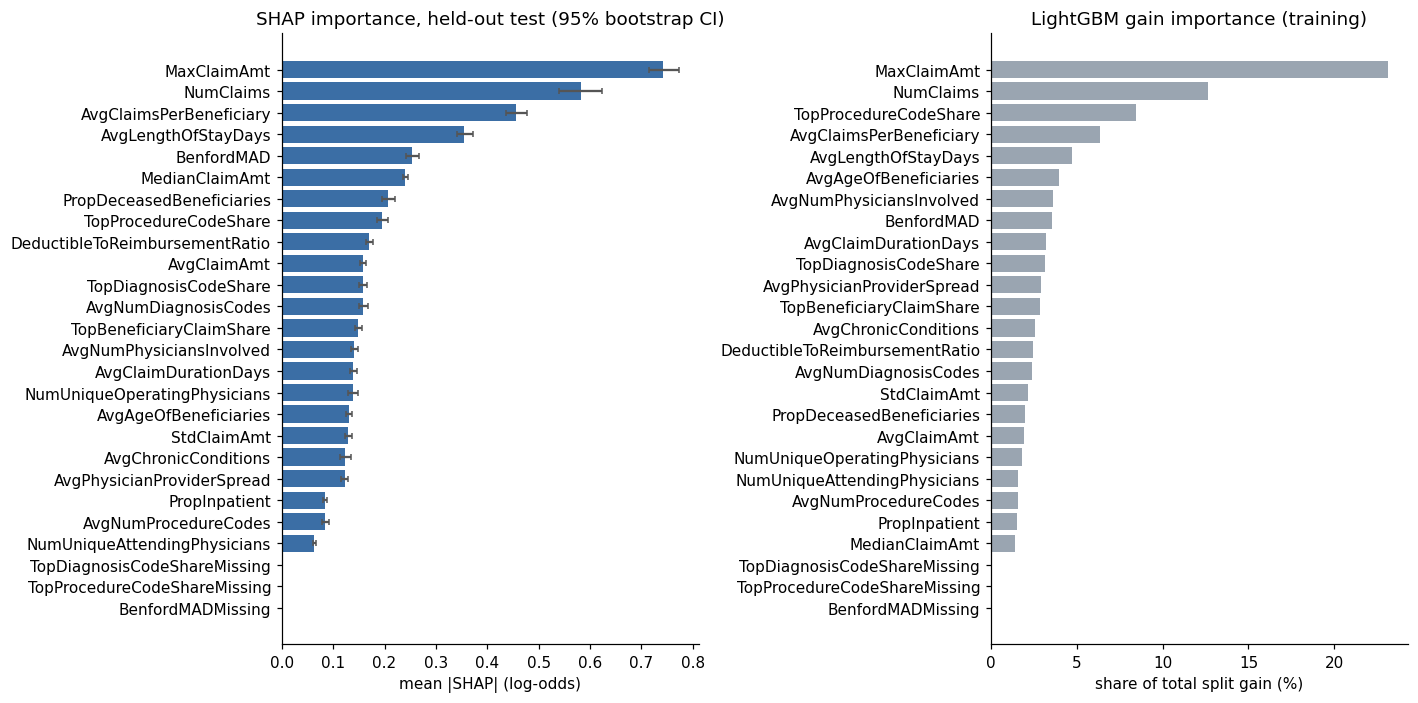

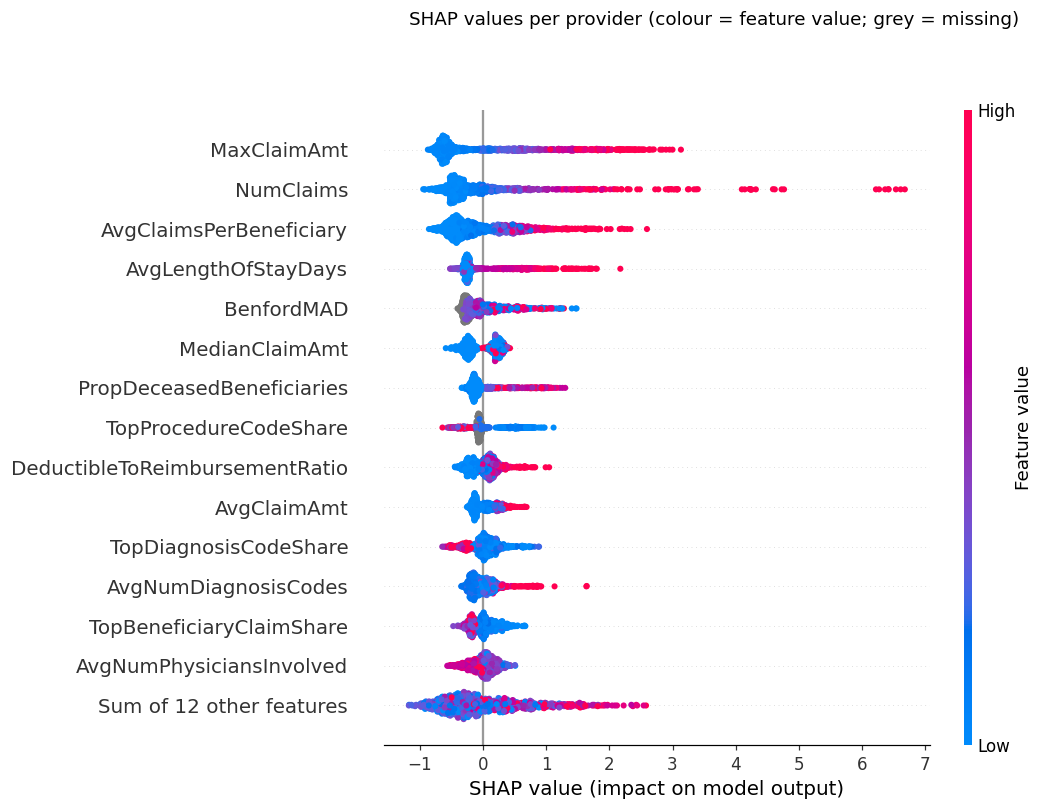

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [1, 1]})
g = glob.iloc[::-1]
axes[0].barh(g.index, g["mean_abs_shap"], xerr=[g["mean_abs_shap"] - g["ci_low"], g["ci_high"] - g["mean_abs_shap"]],
             color="#3b6ea5", ecolor="#555", capsize=2)
axes[0].set_xlabel("mean |SHAP| (log-odds)")
axes[0].set_title("SHAP importance, held-out test (95% bootstrap CI)")
gg = glob.sort_values("gain_rank").iloc[::-1]
axes[1].barh(gg.index, gg["gain_share_pct"], color="#9aa5b1")
axes[1].set_xlabel("share of total split gain (%)")
axes[1].set_title("LightGBM gain importance (training)")
fig.tight_layout()
save_fig(fig, "01_global_importance")
plt.show()

shap.plots.beeswarm(explanation, max_display=15, show=False)
fig = plt.gcf()
fig.suptitle("SHAP values per provider (colour = feature value; grey = missing)", y=1.0)
save_fig(fig, "02_beeswarm")
plt.show()

## 5. Correlated features and feature groups
SHAP divides credit between correlated features in a way that depends on how the trees happened to split. For example, four of the claim-amount features summarise the same distribution. Credit for a shared signal can therefore move between them. Summing SHAP values within a domain group is still exact, because contributions are additive. This makes a **group** ranking more stable to interpret than individual ranks inside a correlated block.

`cancellation` compares the sum of members' mean |SHAP| with the group's mean |SHAP|. A ratio well above 1 means members often push in opposite directions for the same provider.

,n_features,mean_abs_shap,sum_member_mean_abs,mean_shap_fraud,mean_shap_nonfraud,top_member,share_pct,cancellation
group,,,,,,,,
Claim amounts,5,1.1816,1.4417,2.0614,-0.1495,MaxClaimAmt,30.4335,1.2201
Volume & patient concentration,3,0.9872,1.1876,2.1016,-0.1668,NumClaims,25.4282,1.2030
Care setting & stay length,3,0.4663,0.5785,0.5913,-0.1280,AvgLengthOfStayDays,12.0098,1.2407
Coding patterns,6,0.3832,0.5959,0.6699,-0.0556,TopProcedureCodeShare,9.8701,1.5549
Physician network,4,0.3127,0.4656,0.3142,0.0066,AvgNumPhysiciansInvolved,8.0531,1.4891
Beneficiary profile,3,0.2974,0.4614,0.0659,0.0093,PropDeceasedBeneficiaries,7.6614,1.5512
Benford's Law,2,0.2541,0.2541,0.1646,-0.0289,BenfordMAD,6.5438,1.0000


Feature pairs with |Spearman| >= 0.7 on the test providers:


,feature_a,feature_b,spearman,shap_rank_a,shap_rank_b
184,AvgNumProcedureCodes,TopProcedureCodeShareMissing,-0.9640,22,25
31,PropInpatient,AvgNumProcedureCodes,0.9509,21,22
40,PropInpatient,AvgLengthOfStayDays,0.9267,21,4
94,StdClaimAmt,MaxClaimAmt,0.9199,18,1
292,AvgLengthOfStayDays,TopProcedureCodeShareMissing,-0.9087,4,25
44,PropInpatient,TopProcedureCodeShareMissing,-0.9049,21,25
50,AvgClaimAmt,StdClaimAmt,0.9014,10,18
180,AvgNumProcedureCodes,AvgLengthOfStayDays,0.8972,22,4
205,NumUniqueAttendingPhysicians,NumUniqueOperatingPhysicians,0.8948,23,16
17,NumClaims,TopDiagnosisCodeShare,-0.8905,2,11


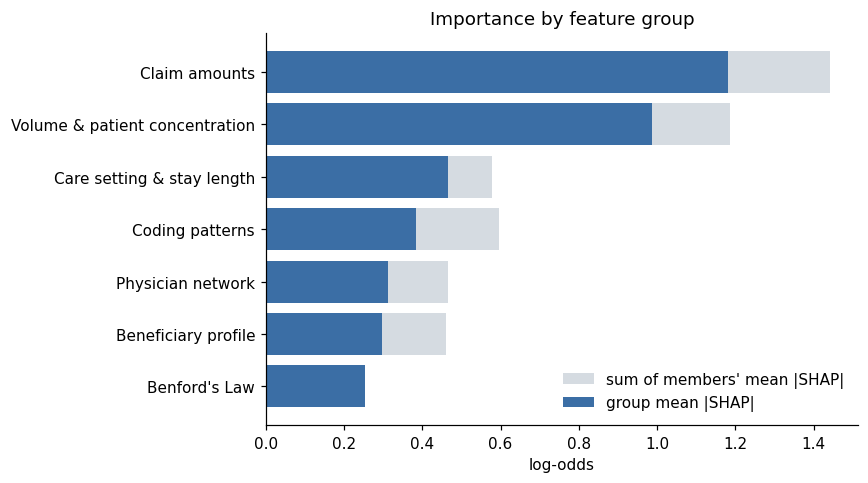

In [7]:
GROUPS = {
    "Volume & patient concentration": ["NumClaims", "AvgClaimsPerBeneficiary", "TopBeneficiaryClaimShare"],
    "Claim amounts": ["AvgClaimAmt", "MedianClaimAmt", "StdClaimAmt", "MaxClaimAmt", "DeductibleToReimbursementRatio"],
    "Care setting & stay length": ["PropInpatient", "AvgClaimDurationDays", "AvgLengthOfStayDays"],
    "Coding patterns": ["AvgNumDiagnosisCodes", "AvgNumProcedureCodes", "TopDiagnosisCodeShare",
                        "TopProcedureCodeShare", "TopDiagnosisCodeShareMissing", "TopProcedureCodeShareMissing"],
    "Physician network": ["AvgNumPhysiciansInvolved", "NumUniqueAttendingPhysicians",
                          "NumUniqueOperatingPhysicians", "AvgPhysicianProviderSpread"],
    "Beneficiary profile": ["AvgAgeOfBeneficiaries", "PropDeceasedBeneficiaries", "AvgChronicConditions"],
    "Benford's Law": ["BenfordMAD", "BenfordMADMissing"],
}
members = [f for cols in GROUPS.values() for f in cols]
assert sorted(members) == sorted(FEATURES) and len(members) == len(set(members)), "Groups must partition the features."
group_of = {f: g for g, cols in GROUPS.items() for f in cols}

group_sv = pd.DataFrame({g: sv[cols].sum(axis=1) for g, cols in GROUPS.items()})
group_tbl = pd.DataFrame({
    "n_features": {g: len(c) for g, c in GROUPS.items()},
    "mean_abs_shap": group_sv.abs().mean(),
    "sum_member_mean_abs": {g: mean_abs[c].sum() for g, c in GROUPS.items()},
    "mean_shap_fraud": group_sv[y == 1].mean(),
    "mean_shap_nonfraud": group_sv[y == 0].mean(),
    "top_member": {g: mean_abs[c].idxmax() for g, c in GROUPS.items()},
})
group_tbl["share_pct"] = 100 * group_tbl["mean_abs_shap"] / group_tbl["mean_abs_shap"].sum()
group_tbl["cancellation"] = group_tbl["sum_member_mean_abs"] / group_tbl["mean_abs_shap"]
group_tbl = group_tbl.sort_values("mean_abs_shap", ascending=False).rename_axis("group")
save_table(group_tbl, "group_importance")
display(group_tbl)

corr = X_raw.corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pairs = pairs[pairs["spearman"].abs() >= 0.7].sort_values("spearman", key=np.abs, ascending=False)
pairs["shap_rank_a"] = pairs["feature_a"].map(glob["rank"])
pairs["shap_rank_b"] = pairs["feature_b"].map(glob["rank"])
save_table(pairs, "correlated_pairs", index=False)
print("Feature pairs with |Spearman| >= 0.7 on the test providers:")
display(pairs)

fig, ax = plt.subplots(figsize=(8, 4.5))
gt = group_tbl.iloc[::-1]
ax.barh(gt.index, gt["sum_member_mean_abs"], color="#d5dbe1", label="sum of members' mean |SHAP|")
ax.barh(gt.index, gt["mean_abs_shap"], color="#3b6ea5", label="group mean |SHAP|")
ax.set_xlabel("log-odds")
ax.set_title("Importance by feature group")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
save_fig(fig, "03_group_importance")
plt.show()
SUMMARY["groups"] = {"table": group_tbl.reset_index(names="group").to_dict("records"),
                     "correlated_pairs": pairs.to_dict("records")}

## 6. Dependence plots and domain features
A dependence plot shows how a feature's SHAP value changes with its value. Each point is one provider and the black line is the binned mean. Point colour shows the **label**, which the model never sees. It shows whether the providers the model pushes up are in fact the labelled ones. Missing values are not plotted; the panel title reports their count and mean SHAP.

The section ends with three checks:
- the three **missing-value columns**: the effect of the imputed value, alongside the (unused) flag;
- the two features the project introduced as less standard signals: `BenfordMAD`, Benford's Law deviation of claim amounts, and `AvgPhysicianProviderSpread`, a physician–provider network feature;
- SHAP **interaction values**, to find the feature pairs whose joint effect matters most.

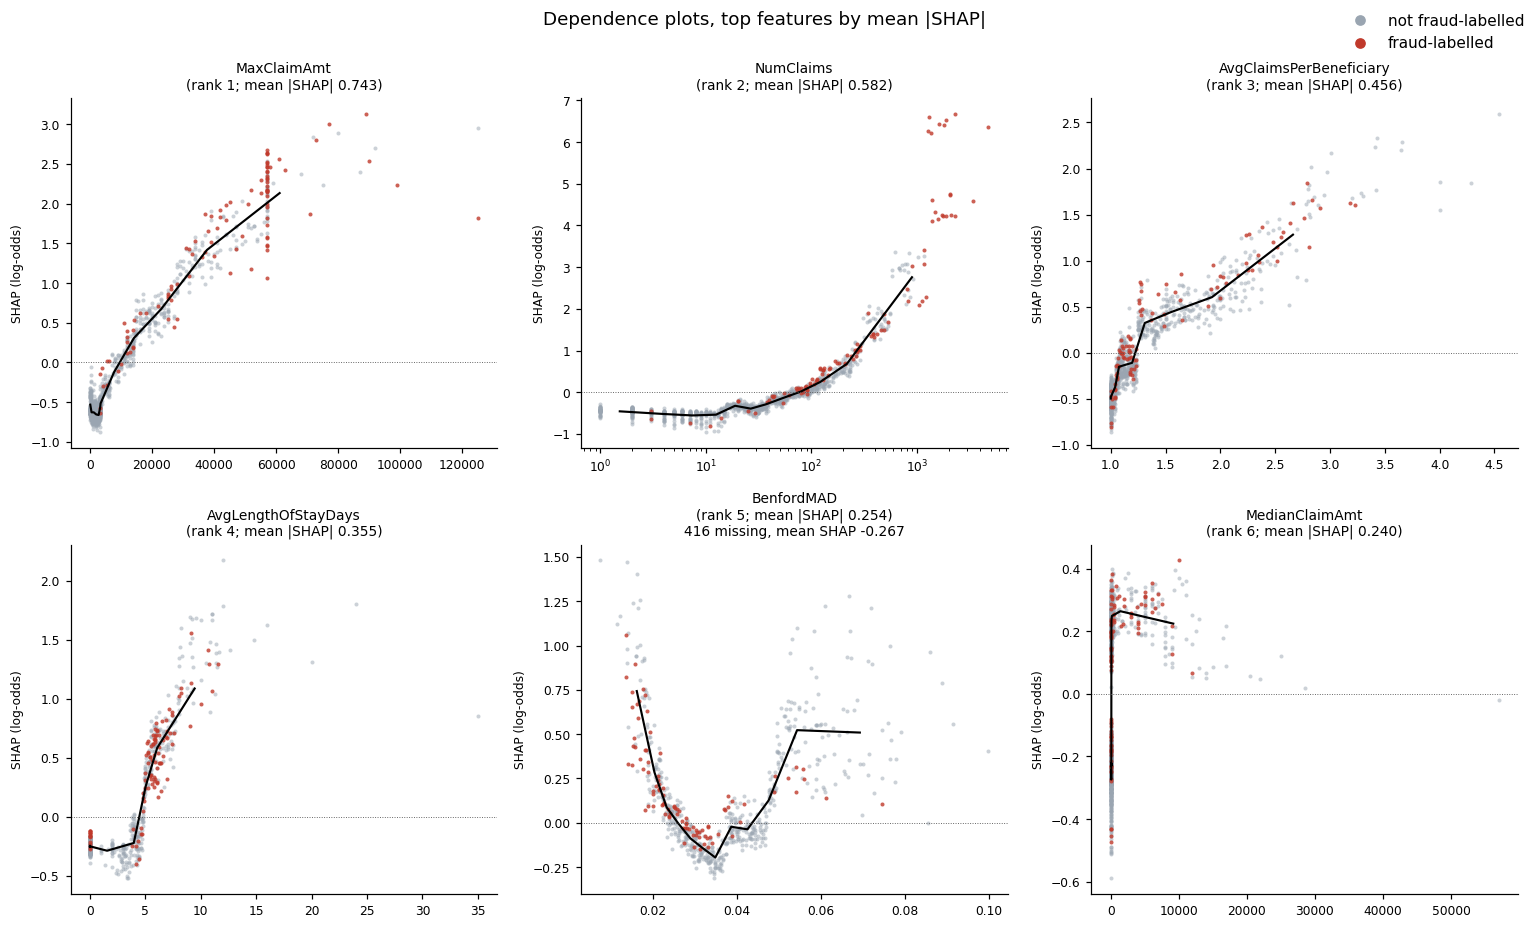

In [8]:
LABEL_COLOURS = {0: "#9aa5b1", 1: "#c0392b"}


def dependence_panel(ax, f):
    x, s = X_raw[f], sv[f]
    ok = x.notna()
    xv, sv_f, yv = x[ok].to_numpy(dtype=float), s[ok].to_numpy(), y[ok.to_numpy()]
    if f in BINARY or x[ok].nunique() <= 2:
        jitter = np.random.default_rng(SEED).uniform(-0.12, 0.12, len(xv))
        for lab in (0, 1):
            m = yv == lab
            ax.scatter(xv[m] + jitter[m], sv_f[m], s=7, alpha=0.5, color=LABEL_COLOURS[lab], lw=0)
        ax.set_xticks(sorted(np.unique(xv)))
    else:
        log = xv.min() > 0 and np.nanpercentile(xv, 99) / max(np.nanmedian(xv), 1e-12) > 20
        for lab in (0, 1):
            m = yv == lab
            ax.scatter(xv[m], sv_f[m], s=7, alpha=0.5 if lab == 0 else 0.8, color=LABEL_COLOURS[lab], lw=0)
        bins = pd.qcut(pd.Series(xv).rank(method="first"), q=min(12, max(2, len(xv) // 40)), labels=False)
        line = pd.DataFrame({"x": xv, "s": sv_f, "b": bins}).groupby("b").mean().sort_values("x")
        ax.plot(line["x"], line["s"], color="black", lw=1.4)
        if log:
            ax.set_xscale("log")
    ax.axhline(0, color="#555", lw=0.6, ls=":")
    n_miss = int((~ok).sum())
    title = f"{f}\n(rank {glob.loc[f, 'rank']}; mean |SHAP| {mean_abs[f]:.3f})"
    if n_miss:
        title += f"\n{n_miss} missing, mean SHAP {s[~ok].mean():+.3f}"
    ax.set_title(title, fontsize=9)
    ax.set_ylabel("SHAP (log-odds)", fontsize=8)
    ax.tick_params(labelsize=8)


top_features = glob.index[:N_DEPENDENCE].tolist()
ncols = 3
nrows = int(np.ceil(len(top_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.2 * nrows))
for ax, f in zip(np.ravel(axes), top_features):
    dependence_panel(ax, f)
for ax in np.ravel(axes)[len(top_features):]:
    ax.axis("off")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=l)
           for l, c in [("not fraud-labelled", LABEL_COLOURS[0]), ("fraud-labelled", LABEL_COLOURS[1])]]
fig.legend(handles=handles, loc="upper right", frameon=False)
fig.suptitle("Dependence plots, top features by mean |SHAP|", y=1.0)
fig.tight_layout()
save_fig(fig, "04_dependence_top")
plt.show()

# Threshold-like behaviour: where along each top feature does the binned mean SHAP cross zero?
cross_rows = []
for f in top_features:
    ok = X_raw[f].notna()
    if f in BINARY or X_raw.loc[ok, f].nunique() <= 2:
        continue
    d = pd.DataFrame({"x": X_raw.loc[ok, f], "s": sv.loc[ok, f]})
    d["bin"] = pd.qcut(d["x"].rank(method="first"), 10, labels=False)
    b = d.groupby("bin").agg(x_min=("x", "min"), x_max=("x", "max"), mean_shap=("s", "mean"))
    b.insert(0, "feature", f)
    cross_rows.append(b.reset_index())
deciles = pd.concat(cross_rows, ignore_index=True) if cross_rows else pd.DataFrame()
save_table(deciles, "dependence_deciles", index=False)
SUMMARY["dependence_deciles"] = deciles.to_dict("records")

n  fraud_rate  mean_shap_value  \
feature               status                                       
TopDiagnosisCodeShare missing     1      0.0000           0.0521   
                      present  1081      0.0934           0.0199   
TopProcedureCodeShare missing   674      0.0163          -0.0687   
                      present   408      0.2206           0.1062   
BenfordMAD            missing   416      0.0120          -0.2672   
                      present   666      0.1441           0.1494   

                               mean_shap_flag  mean_shap_combined  \
feature               status                                        
TopDiagnosisCodeShare missing          0.0000              0.0521   
                      present          0.0000              0.0199   
TopProcedureCodeShare missing          0.0000             -0.0687   
                      present          0.0000              0.1062   
BenfordMAD            missing          0.0000             -0.2672   
                      present          0.0000              0.1494   

                               mean_abs_combined  
feature               status                      
TopDiagnosisCodeShare missing             0.0521  
                      present             0.1582  
TopProcedureCodeShare missing             0.0695  
                      present             0.4050  
BenfordMAD            missing             0.2672  
                      present             0.2458

,rank,rank_ci_low,rank_ci_high,mean_abs_shap,share_pct,direction_spearman,gain_rank
feature,,,,,,,
BenfordMAD,5,5,6,0.2541,5.0968,0.0030,8
AvgPhysicianProviderSpread,20,17,20,0.1228,2.4637,0.4169,11
BenfordMADMissing,26,26,26,0.0000,0.0000,NaN,26


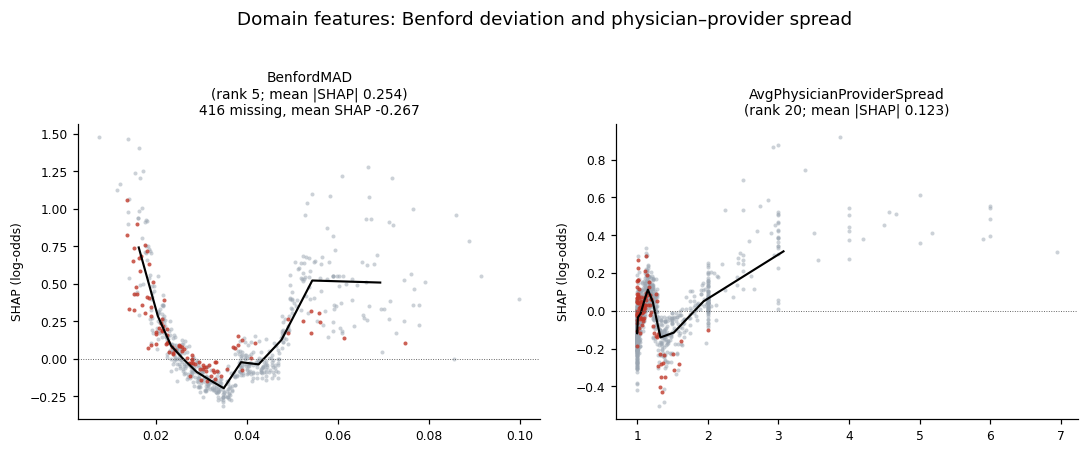

In [9]:
# Missing-value columns: the value (imputed to the training median when missing) and its flag act together
miss_rows = []
for col in RESTORE_NA_COLS:
    flag = f"{col}Missing"
    miss = X_raw[col].isna().to_numpy()
    for status, m in (("missing", miss), ("present", ~miss)):
        if not m.any():
            continue
        miss_rows.append({
            "feature": col, "status": status, "n": int(m.sum()),
            "fraud_rate": float(y[m].mean()),
            "mean_shap_value": float(sv.loc[m, col].mean()),
            "mean_shap_flag": float(sv.loc[m, flag].mean()),
            "mean_shap_combined": float((sv.loc[m, col] + sv.loc[m, flag]).mean()),
            "mean_abs_combined": float((sv.loc[m, col] + sv.loc[m, flag]).abs().mean()),
        })
missing_tbl = pd.DataFrame(miss_rows).set_index(["feature", "status"])
save_table(missing_tbl, "missing_value_effects")
display(missing_tbl)

# Domain features introduced by the project
DOMAIN = ["BenfordMAD", "AvgPhysicianProviderSpread"]
domain_tbl = glob.loc[DOMAIN + ["BenfordMADMissing"], ["rank", "rank_ci_low", "rank_ci_high", "mean_abs_shap",
                                                       "share_pct", "direction_spearman", "gain_rank"]]
display(domain_tbl)
fig, axes = plt.subplots(1, len(DOMAIN), figsize=(10, 4))
for ax, f in zip(np.atleast_1d(axes), DOMAIN):
    dependence_panel(ax, f)
fig.suptitle("Domain features: Benford deviation and physician–provider spread", y=1.02)
fig.tight_layout()
save_fig(fig, "05_dependence_domain")
plt.show()
SUMMARY["missing"] = missing_tbl.reset_index().to_dict("records")
SUMMARY["domain"] = domain_tbl.reset_index(names="feature").to_dict("records")

In [10]:
# SHAP interaction values (path-dependent). Off-diagonal entries are split symmetrically, so a pair's
# total interaction is twice one entry.
interaction_top = None
if RUN_INTERACTIONS:
    t0 = time.time()
    try:
        raw_inter = tree_explainer.shap_interaction_values(X_model)
        inter = np.asarray(raw_inter[-1] if isinstance(raw_inter, list) else raw_inter)
        if inter.ndim == 4:
            inter = inter[..., -1] if inter.shape[-1] == 2 else inter[-1]
        assert inter.shape == (len(X_model), len(FEATURES), len(FEATURES)), inter.shape
        mean_abs_inter = np.abs(inter).mean(axis=0)
        main_effect = pd.Series(np.diag(mean_abs_inter), index=FEATURES)
        iu = np.triu_indices(len(FEATURES), k=1)
        interaction_top = (pd.DataFrame({"feature_a": np.array(FEATURES)[iu[0]],
                                         "feature_b": np.array(FEATURES)[iu[1]],
                                         "mean_abs_interaction": 2 * mean_abs_inter[iu]})
                           .sort_values("mean_abs_interaction", ascending=False).head(TOP_K).reset_index(drop=True))
        total_inter = float(2 * mean_abs_inter[iu].sum())
        print(f"Interaction values computed in {time.time() - t0:.0f}s")
        print(f"Sum of mean |main effects|: {main_effect.sum():.3f}; sum of mean |pairwise interactions|: {total_inter:.3f}")
        display(interaction_top)
        save_table(interaction_top, "top_interactions", index=False)
        SUMMARY["interactions"] = {"top": interaction_top.to_dict("records"),
                                   "sum_main": float(main_effect.sum()), "sum_pairwise": total_inter}
    except Exception as exc:  # optional analysis; record why it was skipped
        print(f"Interaction values not computed: {type(exc).__name__}: {exc}")
        SUMMARY["interactions"] = {"error": f"{type(exc).__name__}: {exc}"}

Interaction values computed in 26s
Sum of mean |main effects|: 5.284; sum of mean |pairwise interactions|: 5.150


,feature_a,feature_b,mean_abs_interaction
0,NumClaims,MaxClaimAmt,0.1132
1,MaxClaimAmt,AvgLengthOfStayDays,0.0694
2,NumClaims,TopBeneficiaryClaimShare,0.0590
3,MaxClaimAmt,AvgClaimsPerBeneficiary,0.0580
4,DeductibleToReimbursementRatio,AvgClaimsPerBeneficiary,0.0567
5,MedianClaimAmt,MaxClaimAmt,0.0566
6,TopDiagnosisCodeShare,BenfordMAD,0.0560
7,MedianClaimAmt,AvgClaimsPerBeneficiary,0.0529
8,AvgNumDiagnosisCodes,AvgClaimsPerBeneficiary,0.0523
9,AvgClaimAmt,MaxClaimAmt,0.0497


## 7. Errors and case studies
The labels now group the explanations into four outcomes at the frozen threshold: true positives (TP), false positives (FP), false negatives (FN) and true negatives (TN). The questions are:
- **False positives:** what makes them look like fraud, and do they resemble the true positives?
- **False negatives:** what keeps them below the threshold?
- **Fragile decisions:** how many decisions rest on one feature? A decision is counted as single-feature when one contribution, in the direction of the decision, is larger than the provider's distance from the threshold in log-odds. Removing that contribution from the additive sum would flip the flag. This is a statement about the attribution, not a counterfactual: changing the feature's value would change other contributions too.

,mean_shap_TP,mean_shap_FP,mean_shap_FN,mean_shap_TN,median_value_TP,median_value_FP,median_value_FN,median_value_TN
feature,,,,,,,,
MaxClaimAmt,1.6139,1.3493,0.5287,-0.2793,52000.0000,36000.0000,14000.0000,3300.0000
NumClaims,1.7642,0.5974,0.3669,-0.1866,251.5000,117.0000,74.0000,24.0000
AvgClaimsPerBeneficiary,0.3745,0.2744,0.3124,-0.0742,1.2297,1.1538,1.4815,1.0686
AvgLengthOfStayDays,0.4220,0.4899,0.4286,-0.1307,5.7593,5.5333,5.9091,0.0000
BenfordMAD,0.1934,0.1709,-0.0001,-0.0493,0.0246,0.0264,0.0296,0.0361
MedianClaimAmt,0.1264,0.0934,-0.0037,-0.0389,100.0000,100.0000,90.0000,80.0000
PropDeceasedBeneficiaries,-0.0037,0.0938,0.0471,-0.0145,0.0063,0.0074,0.0000,0.0000
TopProcedureCodeShare,0.4529,0.3275,-0.0441,-0.0799,0.0952,0.1667,0.3333,0.5000
DeductibleToReimbursementRatio,0.1457,0.1320,0.1341,-0.0133,0.0859,0.0853,0.0734,0.0117


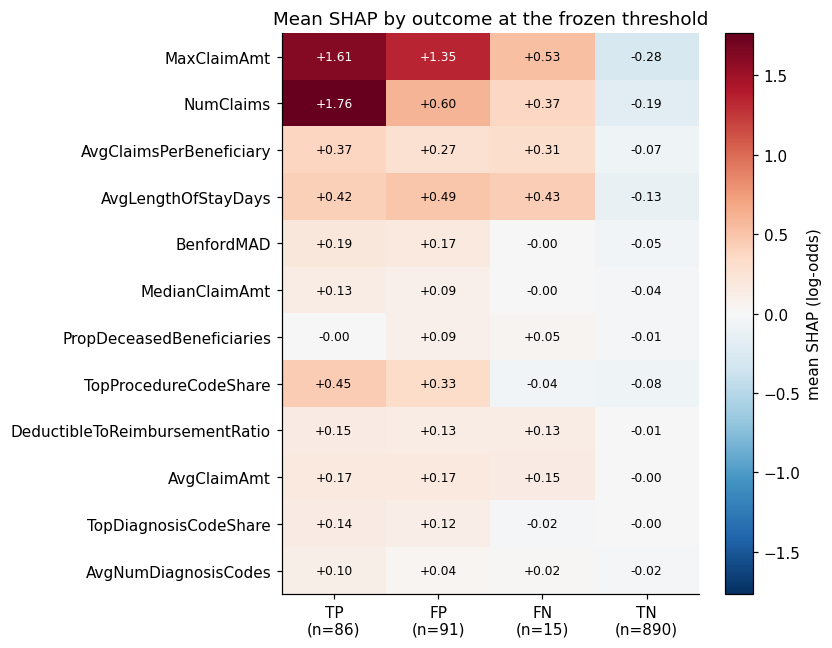

,TP,FP,FN,TN
Volume & patient concentration,2.3519,0.9919,0.6666,-0.2852
Claim amounts,2.2533,1.9474,0.9613,-0.3639
Care setting & stay length,0.6160,0.6396,0.4500,-0.2065
Coding patterns,0.7772,0.5655,0.0545,-0.1191
Physician network,0.3828,0.3598,-0.0793,-0.0295
Beneficiary profile,0.0674,0.1841,0.0576,-0.0085
Benford's Law,0.1934,0.1709,-0.0001,-0.0493
(base value),-5.6894,-5.6894,-5.6894,-5.6894
(mean log-odds score),0.9525,-0.8302,-3.5788,-6.7514


,TP,FP,total
top_positive_driver,,,
MaxClaimAmt,51,61,112
NumClaims,29,15,44
AvgLengthOfStayDays,3,10,13
AvgClaimsPerBeneficiary,3,4,7
TopProcedureCodeShare,0,1,1


In [11]:
top12 = glob.index[:12].tolist()
profile = pd.DataFrame({o: sv.loc[outcome == o, top12].mean() for o in OUTCOMES})
medians = pd.DataFrame({o: X_raw.loc[outcome == o, top12].median() for o in OUTCOMES})
profile_out = profile.add_prefix("mean_shap_").join(medians.add_prefix("median_value_")).rename_axis("feature")
save_table(profile_out, "outcome_profile")
display(profile_out)

fig, ax = plt.subplots(figsize=(7.5, 6))
lim = float(np.abs(profile.to_numpy()).max())
im = ax.imshow(profile.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(OUTCOMES)), [f"{o}\n(n={counts[o]})" for o in OUTCOMES])
ax.set_yticks(range(len(top12)), top12)
for i in range(len(top12)):
    for j in range(len(OUTCOMES)):
        v = profile.iat[i, j]
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 * lim else "black")
fig.colorbar(im, ax=ax, label="mean SHAP (log-odds)")
ax.set_title("Mean SHAP by outcome at the frozen threshold")
fig.tight_layout()
save_fig(fig, "06_outcome_profile")
plt.show()

# Group-level view by outcome (sums within domain groups are exact)
group_profile = pd.DataFrame({o: group_sv[outcome == o].mean() for o in OUTCOMES})
group_profile.loc["(base value)"] = BASE
group_profile.loc["(mean log-odds score)"] = [margin[outcome == o].mean() for o in OUTCOMES]
save_table(group_profile, "outcome_group_profile")
display(group_profile)

# Most frequent top positive driver among flagged providers (what the dashboard lists first)
top_driver = sv.idxmax(axis=1)
driver_tbl = (pd.crosstab(top_driver[flagged], outcome[flagged]).reindex(columns=["TP", "FP"], fill_value=0)
              .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False)
              .rename_axis(index="top_positive_driver", columns=None))
save_table(driver_tbl, "flagged_top_driver")
display(driver_tbl.head(TOP_K))
SUMMARY["outcomes"] = {"profile": profile_out.reset_index(names="feature").to_dict("records"),
                       "group_profile": group_profile.reset_index(names="group").to_dict("records"),
                       "flagged_top_driver": driver_tbl.reset_index(names="feature").to_dict("records")}

In [12]:
# Fragility: does one contribution decide the flag?
distance = margin - THRESHOLD_LOGODDS            # >= 0 when flagged
toward = np.where(flagged[:, None], sv.to_numpy(), -sv.to_numpy())   # contributions in the decision's direction
largest_toward = toward.max(axis=1)
single_feature = largest_toward > np.abs(distance)
near = np.abs(distance) <= NEAR_BAND_LOGODDS

frag = pd.DataFrame({
    "n": counts,
    "near_threshold": pd.Series(near).groupby(outcome).sum(),
    "single_feature_decision": pd.Series(single_feature).groupby(outcome).sum(),
    "median_distance_logodds": pd.Series(np.abs(distance)).groupby(outcome).median(),
}).reindex(OUTCOMES).rename_axis("outcome")
frag["single_feature_pct"] = 100 * frag["single_feature_decision"] / frag["n"]
save_table(frag, "decision_fragility")
display(frag)
deciding = pd.Series(np.array(FEATURES)[toward.argmax(axis=1)][single_feature]).value_counts().head(TOP_K)
print("Feature that alone decides the flag, most frequent:")
display(deciding.to_frame("providers"))

# Importance among providers near the threshold (where review decisions are actually made)
near_imp = sv[near].abs().mean().sort_values(ascending=False)
near_tbl = pd.DataFrame({"mean_abs_shap_near": near_imp, "rank_near": np.arange(1, len(near_imp) + 1),
                         "rank_all": glob.loc[near_imp.index, "rank"]}).rename_axis("feature")
print(f"{int(near.sum())} providers within ±{NEAR_BAND_LOGODDS} log-odds of the threshold "
      f"(scores {sigmoid(THRESHOLD_LOGODDS - NEAR_BAND_LOGODDS):.3f}–{sigmoid(THRESHOLD_LOGODDS + NEAR_BAND_LOGODDS):.3f}).")
display(near_tbl.head(TOP_K))
save_table(near_tbl, "importance_near_threshold")
SUMMARY["fragility"] = {"table": frag.reset_index(names="outcome").to_dict("records"),
                        "deciding_features": deciding.to_dict(), "n_near": int(near.sum()),
                        "near_band_scores": [float(sigmoid(THRESHOLD_LOGODDS - NEAR_BAND_LOGODDS)),
                                             float(sigmoid(THRESHOLD_LOGODDS + NEAR_BAND_LOGODDS))],
                        "near_importance": near_tbl.head(TOP_K).reset_index(names="feature").to_dict("records")}

,n,near_threshold,single_feature_decision,median_distance_logodds,single_feature_pct
outcome,,,,,
TP,86,5,28,3.3997,32.5581
FP,91,19,58,1.1896,63.7363
FN,15,3,3,1.0536,20.0000
TN,890,19,17,4.7765,1.9101


Feature that alone decides the flag, most frequent:


,providers
MaxClaimAmt,47
NumClaims,30
AvgClaimsPerBeneficiary,12
AvgLengthOfStayDays,10
TopProcedureCodeShare,2
MedianClaimAmt,2
AvgNumPhysiciansInvolved,1
TopDiagnosisCodeShare,1
AvgPhysicianProviderSpread,1


46 providers within ±0.5 log-odds of the threshold (scores 0.054–0.134).


,mean_abs_shap_near,rank_near,rank_all
feature,,,
MaxClaimAmt,1.0576,1,1
NumClaims,0.8685,2,2
AvgClaimsPerBeneficiary,0.5751,3,3
AvgLengthOfStayDays,0.5615,4,4
TopProcedureCodeShare,0.3422,5,8
BenfordMAD,0.2748,6,5
MedianClaimAmt,0.2702,7,6
StdClaimAmt,0.2308,8,18
AvgNumDiagnosisCodes,0.2028,9,12


### Case studies
The five providers below are chosen by fixed rules, not by hand, so the selection is reproducible:
1. the highest-scoring true positive;
2. the true positive closest above the threshold;
3. the highest-scoring false positive;
4. the false negative closest below the threshold (a near miss);
5. the lowest-scoring false negative (a confident miss).

Each waterfall starts at the base value and adds the largest contributions. The remaining features are pooled into one bar. Feature values are shown as the provider's original values; `nan` means the value was missing and the model used the training median.

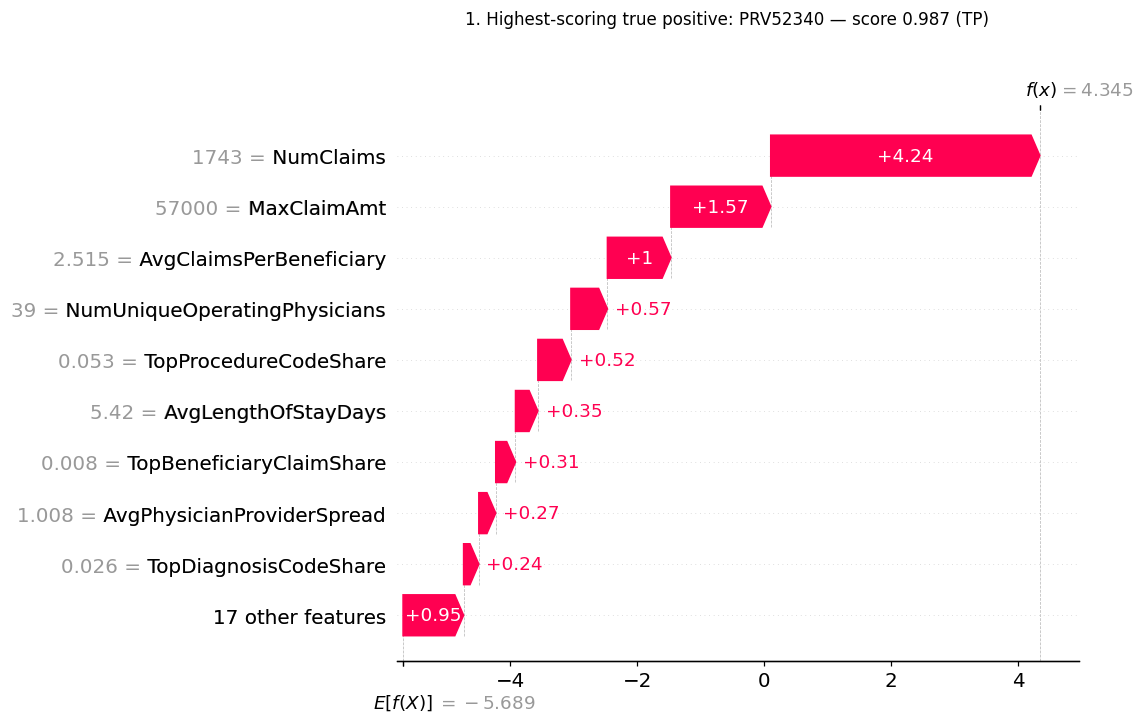

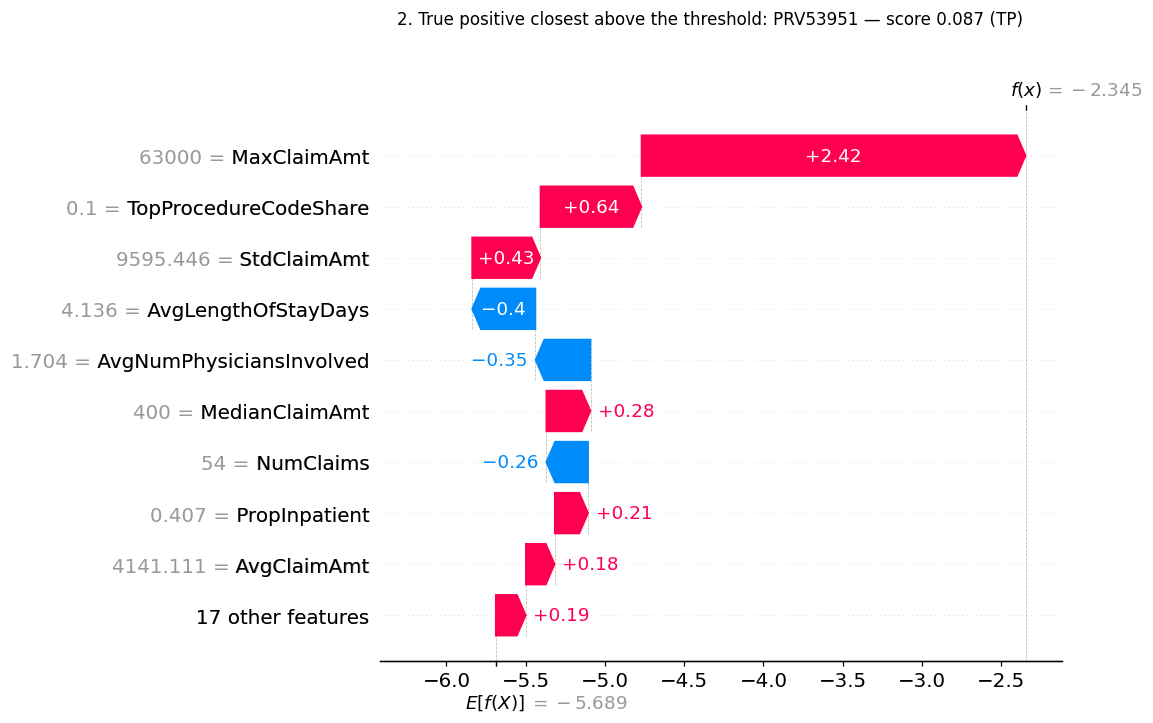

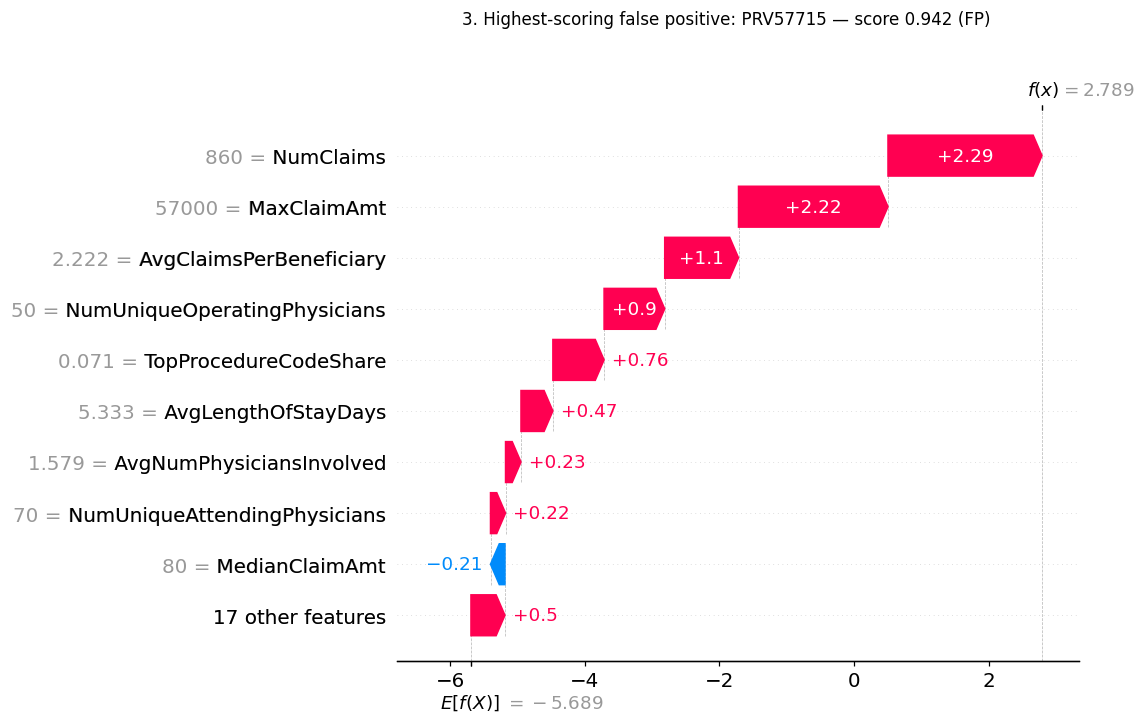

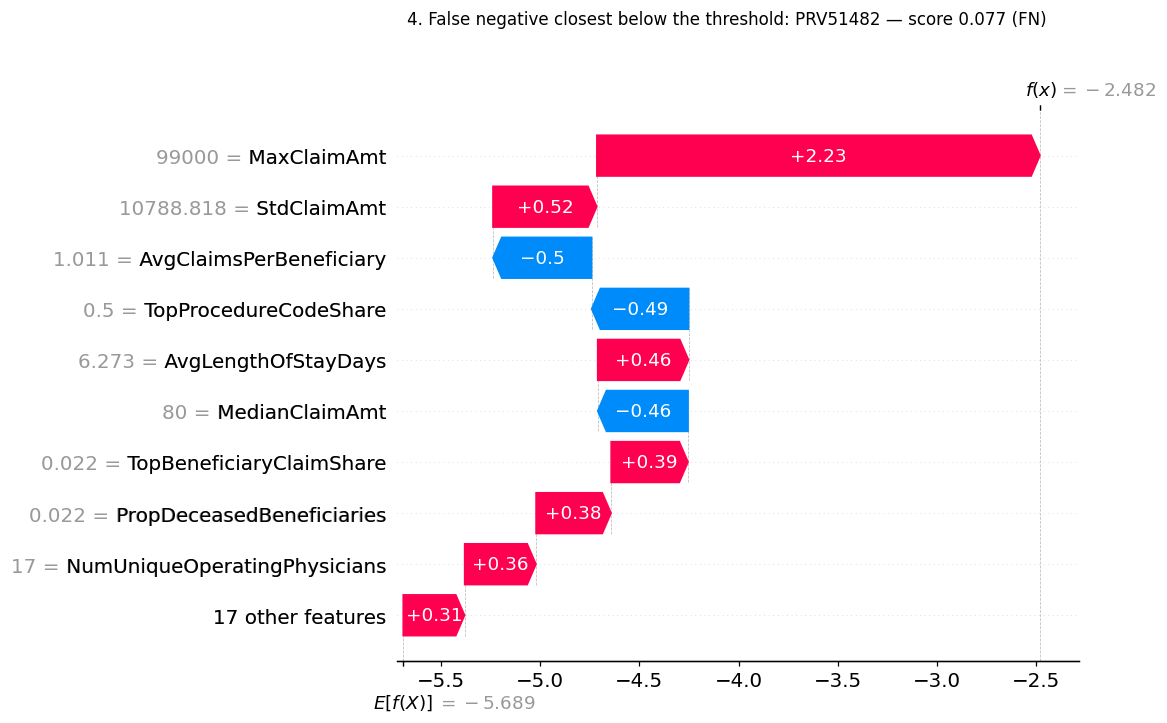

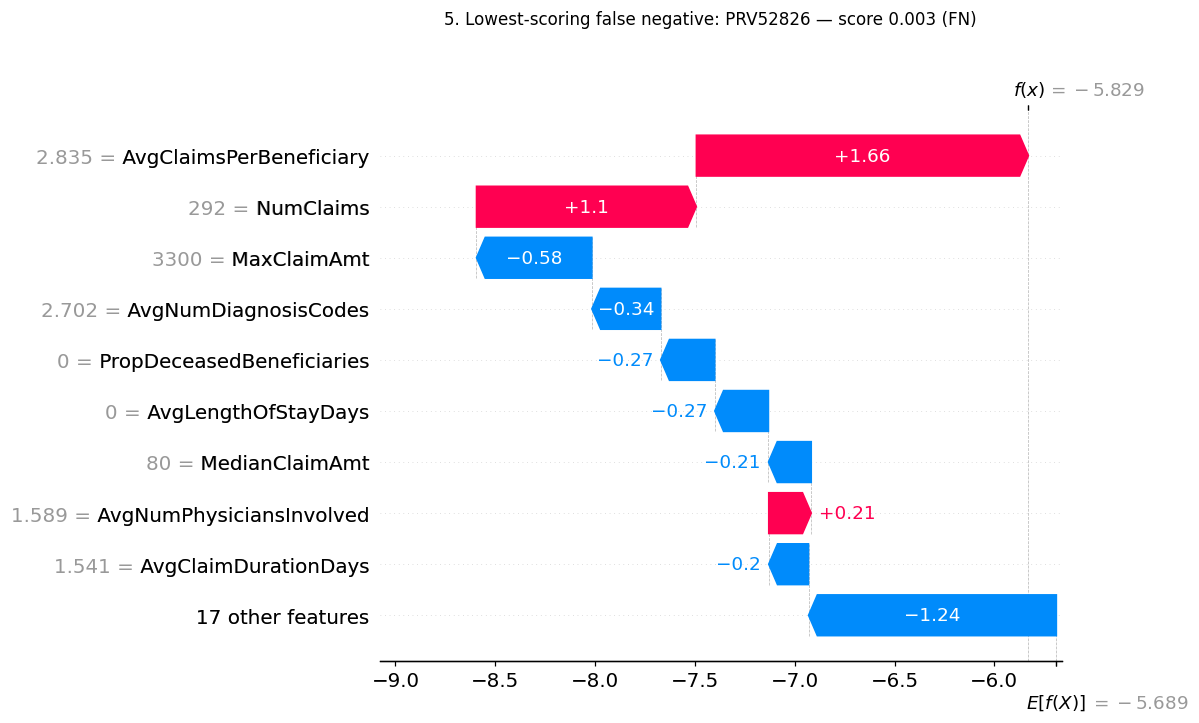

,case,Provider,outcome,score,logodds_minus_threshold,top_drivers
0,Highest-scoring true positive,PRV52340,TP,0.9872,6.7071,NumClaims=1743 (+4.24); MaxClaimAmt=5.7e+04 (+1.57); AvgClaimsPerBeneficiary=2.515 (+1.00); NumUniqueOperatingPhysicians=39 (+0.57); TopProcedureCodeShare=0.0531 (+0.52)
1,True positive closest above the threshold,PRV53951,TP,0.0874,0.0168,MaxClaimAmt=6.3e+04 (+2.42); TopProcedureCodeShare=0.1 (+0.64); StdClaimAmt=9595 (+0.43); AvgLengthOfStayDays=4.136 (-0.40); AvgNumPhysiciansInvolved=1.704 (-0.35)
2,Highest-scoring false positive,PRV57715,FP,0.9421,5.1509,NumClaims=860 (+2.29); MaxClaimAmt=5.7e+04 (+2.22); AvgClaimsPerBeneficiary=2.222 (+1.10); NumUniqueOperatingPhysicians=50 (+0.90); TopProcedureCodeShare=0.07143 (+0.76)
3,False negative closest below the threshold,PRV51482,FN,0.0771,-0.1197,MaxClaimAmt=9.9e+04 (+2.23); StdClaimAmt=1.079e+04 (+0.52); AvgClaimsPerBeneficiary=1.011 (-0.50); TopProcedureCodeShare=0.5 (-0.49); AvgLengthOfStayDays=6.273 (+0.46)
4,Lowest-scoring false negative,PRV52826,FN,0.0029,-3.4673,AvgClaimsPerBeneficiary=2.835 (+1.66); NumClaims=292 (+1.10); MaxClaimAmt=3300 (-0.58); AvgNumDiagnosisCodes=2.702 (-0.34); PropDeceasedBeneficiaries=0 (-0.27)


In [13]:
def pick(o, by, largest=True):
    idx = np.flatnonzero(outcome == o)
    if len(idx) == 0:
        return None
    vals = by[idx]
    return int(idx[np.argmax(vals) if largest else np.argmin(vals)])


CASES = {
    "Highest-scoring true positive": pick("TP", score),
    "True positive closest above the threshold": pick("TP", score, largest=False),
    "Highest-scoring false positive": pick("FP", score),
    "False negative closest below the threshold": pick("FN", score),
    "Lowest-scoring false negative": pick("FN", score, largest=False),
}
case_rows = []
for k, (label, i) in enumerate(CASES.items(), start=1):
    if i is None:
        continue
    row = sv.iloc[i]
    top = row.abs().sort_values(ascending=False).index[:5]
    case_rows.append({"case": label, ID_COL: ids[i], "outcome": outcome[i], "score": score[i],
                      "logodds_minus_threshold": distance[i],
                      "top_drivers": "; ".join(f"{f}={X_raw.iloc[i][f]:.4g} ({row[f]:+.2f})" for f in top)})
    shap.plots.waterfall(explanation[i], max_display=10, show=False)
    fig = plt.gcf()
    fig.suptitle(f"{k}. {label}: {ids[i]} — score {score[i]:.3f} ({outcome[i]})", y=1.02, fontsize=11)
    save_fig(fig, f"07_case_{k}_{outcome[i]}")
    plt.show()
cases = pd.DataFrame(case_rows)
save_table(cases, "case_studies", index=False)
with pd.option_context("display.max_colwidth", None):
    display(cases)
SUMMARY["cases"] = cases.to_dict("records")

## 8. Robustness checks
1. **Additivity and implementation:** shown in section 3.
2. **Ranking uncertainty:** the bootstrap rank intervals in section 4.
3. **Path-dependent vs interventional SHAP.** Path-dependent TreeSHAP takes the expectation over the training distribution as stored in the trees. With correlated features, it can give credit to a feature the model does not use directly. Interventional TreeSHAP instead breaks feature dependence using a background sample of development providers. It answers a more causal-in-the-model question: what happens to the score if this feature is replaced by background values? If both methods agree on the ranking, the conclusions do not hinge on that choice. The background is a random sample of the development providers. Only their features are used, never their labels.

 92%|==================  | 993/1082 [00:11<00:00]       

Interventional SHAP computed in 12s; base value -5.8948; additivity gap 2.28e-07


,path_dependent,interventional,rank_path,rank_interventional
feature,,,,
MaxClaimAmt,0.7430,0.5950,1,2
NumClaims,0.5821,0.6059,2,1
AvgClaimsPerBeneficiary,0.4564,0.4714,3,3
AvgLengthOfStayDays,0.3550,0.3540,4,4
BenfordMAD,0.2541,0.2788,5,5
MedianClaimAmt,0.2402,0.2433,6,6
PropDeceasedBeneficiaries,0.2072,0.2286,7,7
TopProcedureCodeShare,0.1960,0.1604,8,10
DeductibleToReimbursementRatio,0.1704,0.1530,9,15


Spearman correlation of global importance (path vs interventional): 0.961; top-10 overlap 9/10
Same top driver for 78.3% of providers; median per-provider Spearman of SHAP vectors 0.971


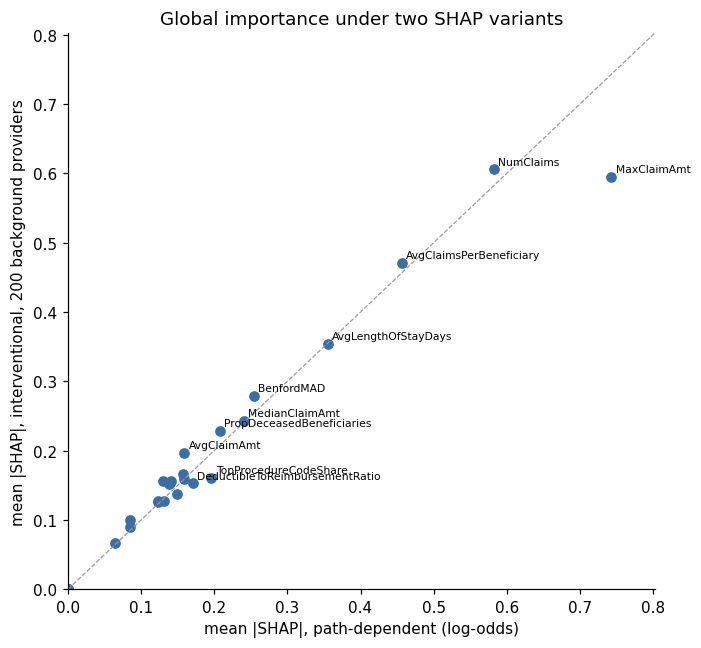

In [14]:
train = load_table(TRAIN_PATH)
background = preprocess(restore_missing(train[FEATURES], RESTORE_NA_COLS)).sample(BACKGROUND_SIZE, random_state=SEED)
t0 = time.time()
int_explainer = shap.TreeExplainer(model, data=background, feature_perturbation="interventional", model_output="raw")
sv_int = pd.DataFrame(as_positive_class(int_explainer.shap_values(X_model, check_additivity=False)),
                      columns=FEATURES, index=X_model.index)
base_int = float(np.atleast_1d(int_explainer.expected_value)[-1])
gap_int = float(np.max(np.abs(sv_int.sum(axis=1).to_numpy() + base_int - margin)))
print(f"Interventional SHAP computed in {time.time() - t0:.0f}s; base value {base_int:.4f}; additivity gap {gap_int:.2e}")

mean_abs_int = sv_int.abs().mean()
cmp = pd.DataFrame({"path_dependent": mean_abs, "interventional": mean_abs_int})
cmp["rank_path"] = cmp["path_dependent"].rank(ascending=False, method="first").astype(int)
cmp["rank_interventional"] = cmp["interventional"].rank(ascending=False, method="first").astype(int)
cmp = cmp.sort_values("rank_path").rename_axis("feature")
rho_methods = spearmanr(cmp["path_dependent"], cmp["interventional"]).statistic
overlap = len(set(cmp.index[:TOP_K]) & set(cmp.sort_values("rank_interventional").index[:TOP_K]))
same_top1 = float((sv.abs().idxmax(axis=1) == sv_int.abs().idxmax(axis=1)).mean())
row_corr = np.array([spearmanr(a, b).statistic for a, b in zip(sv.to_numpy(), sv_int.to_numpy())])
save_table(cmp, "path_vs_interventional")
display(cmp)
print(f"Spearman correlation of global importance (path vs interventional): {rho_methods:.3f}; "
      f"top-{TOP_K} overlap {overlap}/{TOP_K}")
print(f"Same top driver for {same_top1:.1%} of providers; median per-provider Spearman of SHAP vectors {np.median(row_corr):.3f}")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(cmp["path_dependent"], cmp["interventional"], color="#3b6ea5")
for f, r in cmp.head(TOP_K).iterrows():
    ax.annotate(f, (r["path_dependent"], r["interventional"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
lim = float(cmp[["path_dependent", "interventional"]].to_numpy().max()) * 1.08
ax.plot([0, lim], [0, lim], color="#999", ls="--", lw=0.8)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("mean |SHAP|, path-dependent (log-odds)")
ax.set_ylabel(f"mean |SHAP|, interventional, {BACKGROUND_SIZE} background providers")
ax.set_title("Global importance under two SHAP variants")
fig.tight_layout()
save_fig(fig, "08_path_vs_interventional")
plt.show()
SUMMARY["robustness"] = {"background_size": BACKGROUND_SIZE, "interventional_base": base_int,
                         "interventional_additivity_gap": gap_int, "spearman_global": rho_methods,
                         "topk_overlap": overlap, "same_top_driver_share": same_top1,
                         "median_row_spearman": float(np.median(row_corr)),
                         "table": cmp.reset_index(names="feature").to_dict("records")}

## 9. Benford follow-up: what does `BenfordMAD` measure?
Section 6 showed that `BenfordMAD` ranks 5th by mean |SHAP| but has a **U-shaped** effect: both very conforming and strongly deviating providers are pushed up. This section checks what the feature actually captures. It changes nothing in the model.

1. **Do the claim amounts suit Benford's Law?** This compares the first-digit distribution of `InscClaimAmtReimbursed` across all claims with Benford's Law, overall and by claim type. It uses amounts and claim type only, no labels.
2. **How does the feature depend on claim count?** Even perfectly Benford-conforming data has a non-zero MAD that shrinks as the sample grows. The expected MAD at each provider's claim count is simulated (500 multinomial draws per count).
3. **Is there a digit signal beyond size and case mix?** Each provider's deviation is compared with what chance would produce at its claim count, under two baselines:
   - perfect Benford;
   - the dataset's **own** first-digit pattern for inpatient and outpatient claims, mixed in the provider's own proportions.

   Fraud-labelled and other **development** providers are then compared with Cohen's *d*, overall (with a 1,000-sample bootstrap interval) and within claim-count quintiles.
4. **Link back to SHAP.** The test-set U-shape is tabulated against fraud rate and claim count.

Development labels are used for step 3; test labels are used only descriptively in step 4, as in section 7. **Team decision (27 October 2026):** the report presents per-provider Benford deviation as a tested method with a qualified result, not as a working fraud detector.

,All claims,Inpatient,Outpatient
claims,558211,40474,517737
zero_amount_share,0.0370,0.0268,0.0378
mad_vs_benford,0.0183,0.0278,0.0175
nigrini,nonconformity,nonconformity,nonconformity
multiple_of_100_share,0.4744,0.9993,0.4329
multiple_of_1000_share,0.0837,0.9919,0.0119
distinct_amounts,437,145,341
top10_amounts_share,0.6588,0.7255,0.7107
orders_of_magnitude_p1_p99,3.2304,1.7559,2.5185
digit_1,0.2379,0.2618,0.2360


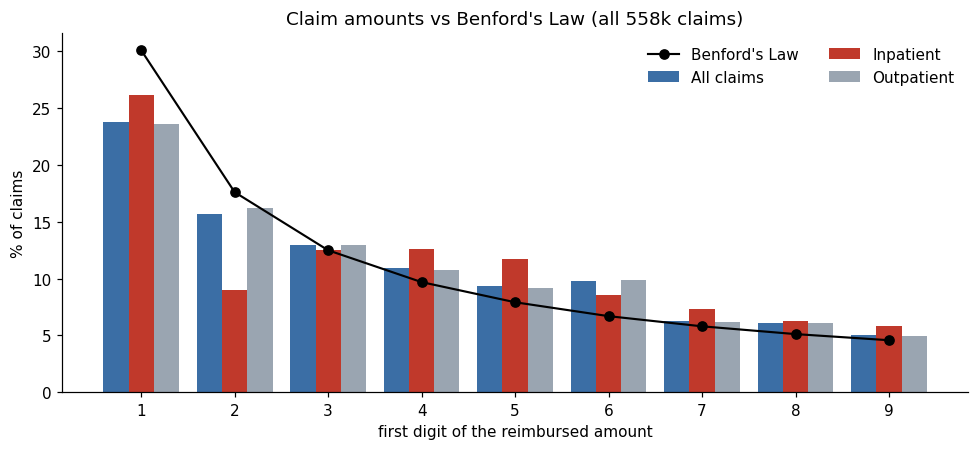

In [15]:
CLAIMS_PATH = ROOT / "data" / "processed" / "claims_cleaned.csv"
claims = pd.read_csv(CLAIMS_PATH, usecols=[ID_COL, "ClaimType", "InscClaimAmtReimbursed"])
claims[ID_COL] = claims[ID_COL].astype(str)
BENFORD = np.log10(1 + 1 / np.arange(1, 10))
# Nigrini (2012) first-digit MAD conformity ranges
NIGRINI = [(0.006, "close conformity"), (0.012, "acceptable conformity"),
           (0.015, "marginally acceptable conformity"), (np.inf, "nonconformity")]


def first_digit(x):
    x = np.asarray(x, dtype=float)
    x = x[x > 0]
    return np.clip((x / 10 ** np.floor(np.log10(x) + 1e-9)).astype(int), 1, 9)


def digit_props(x):
    d = first_digit(x)
    return np.bincount(d, minlength=10)[1:] / len(d)


amounts = claims["InscClaimAmtReimbursed"]
digit_rows = {}
for name, mask in [("All claims", np.ones(len(claims), bool)),
                   ("Inpatient", claims["ClaimType"].eq("Inpatient").to_numpy()),
                   ("Outpatient", claims["ClaimType"].eq("Outpatient").to_numpy())]:
    x = amounts[mask]
    pos_x = x[x > 0]
    props = digit_props(x)
    mad = float(np.abs(props - BENFORD).mean())
    digit_rows[name] = {
        "claims": int(mask.sum()), "zero_amount_share": float((x <= 0).mean()),
        "mad_vs_benford": mad, "nigrini": next(label for cut, label in NIGRINI if mad <= cut),
        "multiple_of_100_share": float((pos_x % 100 == 0).mean()),
        "multiple_of_1000_share": float((pos_x % 1000 == 0).mean()),
        "distinct_amounts": int(pos_x.nunique()),
        "top10_amounts_share": float(pos_x.value_counts(normalize=True).head(10).sum()),
        "orders_of_magnitude_p1_p99": float(np.log10(pos_x.quantile(0.99) / pos_x.quantile(0.01))),
        **{f"digit_{k}": float(v) for k, v in zip(range(1, 10), props)},
    }
digit_tbl = pd.DataFrame(digit_rows).T
save_table(digit_tbl, "benford_claim_digits")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(digit_tbl.T)

fig, ax = plt.subplots(figsize=(9, 4.2))
width = 0.27
for k, (name, colour) in enumerate([("All claims", "#3b6ea5"), ("Inpatient", "#c0392b"), ("Outpatient", "#9aa5b1")]):
    ax.bar(np.arange(1, 10) + (k - 1) * width, 100 * digit_tbl.loc[name, [f"digit_{d}" for d in range(1, 10)]].astype(float),
           width=width, color=colour, label=name)
ax.plot(np.arange(1, 10), 100 * BENFORD, color="black", marker="o", lw=1.4, label="Benford's Law")
ax.set_xticks(range(1, 10))
ax.set_xlabel("first digit of the reimbursed amount")
ax.set_ylabel("% of claims")
ax.set_title("Claim amounts vs Benford's Law (all 558k claims)")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
save_fig(fig, "09_benford_claim_digits")
plt.show()

Recomputed BenfordMAD vs feature table, max abs difference: 1.1e-16
BenfordMADMissing == (fewer than 20 claims) for every development provider: True


Development providers with a Benford value: 2654 (375 fraud-labelled)


,d_fraud_minus_other,d_ci_low,d_ci_high,median_fraud,median_other,spearman_with_claim_count
measure,,,,,,
BenfordMAD (as used by the model),-0.4738,-0.5734,-0.3768,0.0267,0.0346,-0.7588
"MAD / chance, perfect-Benford baseline",0.9324,0.7927,1.0825,1.5592,1.2246,0.4956
"MAD / chance, own case-mix baseline",0.0666,-0.0355,0.1792,0.9948,0.9780,-0.0132


,providers,fraud_labelled,fraud_rate,mean_mad_fraud,mean_mad_other,d[BenfordMAD],d[ratio_benford],d[ratio_mix]
claims_band,,,,,,,,
17–31,540,27,0.0500,0.0550,0.0532,0.1191,0.0147,0.0302
32–51,540,40,0.0741,0.0437,0.0427,0.0906,0.1215,0.0620
52–84,517,46,0.0890,0.0381,0.0343,0.3814,0.3834,0.1349
85–177,527,82,0.1556,0.0299,0.0284,0.1921,0.2709,0.1113
178–7907,530,180,0.3396,0.0221,0.0226,-0.0969,0.6661,0.0768


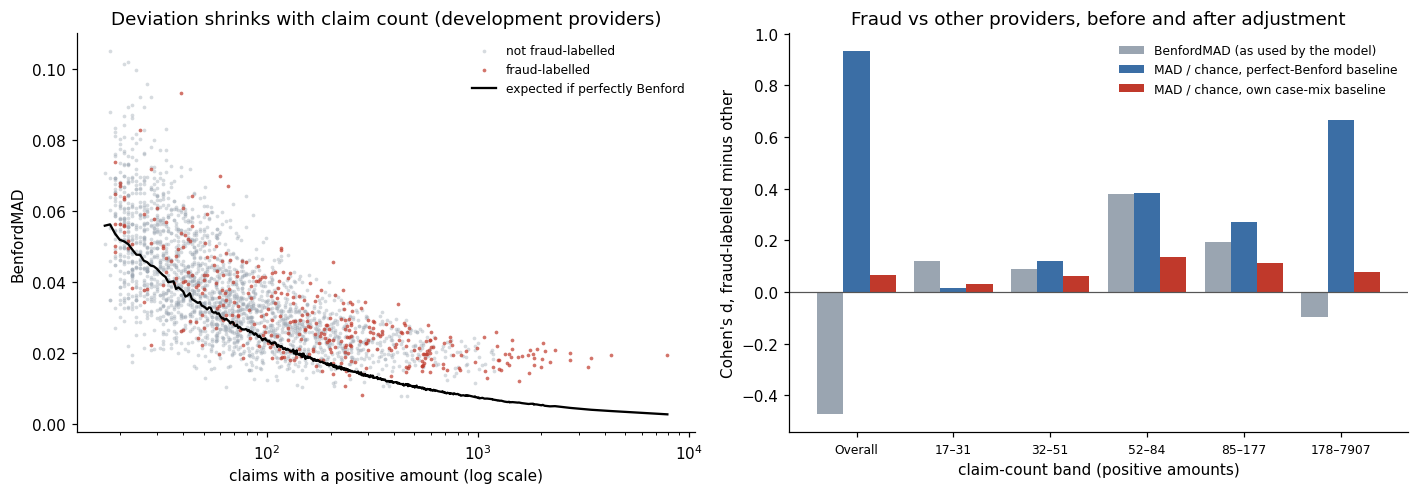

In [16]:
# Per-provider first-digit counts (positive amounts only, as in src/features.py)
pos_claims = claims[claims["InscClaimAmtReimbursed"] > 0].copy()
pos_claims["digit"] = first_digit(pos_claims["InscClaimAmtReimbursed"])
digit_counts = pd.crosstab(pos_claims[ID_COL], pos_claims["digit"]).reindex(columns=range(1, 10), fill_value=0)
n_pos = digit_counts.sum(axis=1)
mad_recomputed = (digit_counts.div(n_pos, axis=0) - BENFORD).abs().mean(axis=1)

dev = train[train["BenfordMADMissing"] == 0][[ID_COL, TARGET, "BenfordMAD", "NumClaims"]].copy()
recompute_gap = float(np.max(np.abs(mad_recomputed.reindex(dev[ID_COL]).to_numpy() - dev["BenfordMAD"].to_numpy())))
print(f"Recomputed BenfordMAD vs feature table, max abs difference: {recompute_gap:.1e}")
assert recompute_gap < 1e-9, "Recomputed BenfordMAD does not match the feature table."
claims_all = claims.groupby(ID_COL).size()
missing_is_small = bool(((claims_all.reindex(train[ID_COL]) < 20).to_numpy()
                         == (train["BenfordMADMissing"] == 1).to_numpy()).all())
print(f"BenfordMADMissing == (fewer than 20 claims) for every development provider: {missing_is_small}")

dev["n_digits"] = n_pos.reindex(dev[ID_COL]).to_numpy()
ip_share = pos_claims.groupby(ID_COL)["ClaimType"].apply(lambda s: float((s == "Inpatient").mean()))
dev["inpatient_share"] = ip_share.reindex(dev[ID_COL]).to_numpy()

# Baseline A: perfect Benford. Expected MAD of a perfectly conforming sample of n amounts.
rng_bf = np.random.default_rng(SEED)
expected_benford = {int(n): float(np.abs(rng_bf.multinomial(int(n), BENFORD, size=500) / n - BENFORD).mean())
                    for n in np.unique(dev["n_digits"])}
dev["expected_mad_benford"] = dev["n_digits"].map(expected_benford)
dev["ratio_benford"] = dev["BenfordMAD"] / dev["expected_mad_benford"]

# Baseline B: the dataset's own digit pattern per claim type, mixed by the provider's inpatient share.
type_digits = (pos_claims.groupby("ClaimType")["digit"].value_counts(normalize=True)
               .unstack().reindex(columns=range(1, 10), fill_value=0))
mix = dev["inpatient_share"].to_numpy()[:, None]
baseline = mix * type_digits.loc["Inpatient"].to_numpy() + (1 - mix) * type_digits.loc["Outpatient"].to_numpy()
observed = digit_counts.div(n_pos, axis=0).reindex(dev[ID_COL]).to_numpy()
dev["mad_vs_mix"] = np.abs(observed - baseline).mean(axis=1)
dev["expected_mad_mix"] = [float(np.abs(rng_bf.multinomial(int(n), b, size=500) / n - b).mean())
                           for n, b in zip(dev["n_digits"], baseline)]
dev["ratio_mix"] = dev["mad_vs_mix"] / dev["expected_mad_mix"]


def cohen_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return float((a.mean() - b.mean()) / pooled)


MEASURES = {"BenfordMAD (as used by the model)": "BenfordMAD",
            "MAD / chance, perfect-Benford baseline": "ratio_benford",
            "MAD / chance, own case-mix baseline": "ratio_mix"}
is_fraud = dev[TARGET].to_numpy() == 1
f_idx, nf_idx = np.flatnonzero(is_fraud), np.flatnonzero(~is_fraud)
rng_boot = np.random.default_rng(SEED)
overall_rows = []
for label, col in MEASURES.items():
    v = dev[col].to_numpy()
    boots = [cohen_d(v[rng_boot.choice(f_idx, len(f_idx))], v[rng_boot.choice(nf_idx, len(nf_idx))]) for _ in range(N_BOOT)]
    overall_rows.append({"measure": label, "d_fraud_minus_other": cohen_d(v[is_fraud], v[~is_fraud]),
                         "d_ci_low": float(np.percentile(boots, 2.5)), "d_ci_high": float(np.percentile(boots, 97.5)),
                         "median_fraud": float(np.median(v[is_fraud])), "median_other": float(np.median(v[~is_fraud])),
                         "spearman_with_claim_count": float(dev[[col, "n_digits"]].corr("spearman").iloc[0, 1])})
benford_overall = pd.DataFrame(overall_rows).set_index("measure")
print(f"Development providers with a Benford value: {len(dev)} ({int(is_fraud.sum())} fraud-labelled)")
display(benford_overall)

dev["claims_band"] = pd.qcut(dev["n_digits"], 5)
band_rows = []
for band, g in dev.groupby("claims_band", observed=True):
    gf, gn = g[g[TARGET] == 1], g[g[TARGET] == 0]
    row = {"claims_band": f"{int(np.floor(band.left)) + 1}–{int(band.right)}", "providers": len(g),
           "fraud_labelled": len(gf), "fraud_rate": float(g[TARGET].mean()),
           "mean_mad_fraud": float(gf["BenfordMAD"].mean()), "mean_mad_other": float(gn["BenfordMAD"].mean())}
    for label, col in MEASURES.items():
        row[f"d[{col}]"] = cohen_d(gf[col], gn[col])
    band_rows.append(row)
benford_bands = pd.DataFrame(band_rows).set_index("claims_band")
display(benford_bands)
save_table(benford_overall, "benford_size_adjusted_overall")
save_table(benford_bands, "benford_size_adjusted_by_claims")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
for lab in (0, 1):
    m = dev[TARGET].to_numpy() == lab
    ax.scatter(dev["n_digits"][m], dev["BenfordMAD"][m], s=6, alpha=0.4 if lab == 0 else 0.7,
               color=LABEL_COLOURS[lab], lw=0, label="fraud-labelled" if lab else "not fraud-labelled")
grid_n = np.array(sorted(expected_benford))
ax.plot(grid_n, [expected_benford[n] for n in grid_n], color="black", lw=1.5, label="expected if perfectly Benford")
ax.set_xscale("log")
ax.set_xlabel("claims with a positive amount (log scale)")
ax.set_ylabel("BenfordMAD")
ax.set_title("Deviation shrinks with claim count (development providers)")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
cols = list(MEASURES.values())
labels = ["Overall"] + benford_bands.index.tolist()
values = np.array([[benford_overall.loc[m, "d_fraud_minus_other"] for m in MEASURES]]
                  + [[benford_bands.loc[b, f"d[{c}]"] for c in cols] for b in benford_bands.index])
x = np.arange(len(labels))
for k, (label, colour) in enumerate(zip(MEASURES, ["#9aa5b1", "#3b6ea5", "#c0392b"])):
    ax.bar(x + (k - 1) * 0.27, values[:, k], width=0.27, color=colour, label=label)
ax.axhline(0, color="#555", lw=0.8)
ax.set_xticks(x, labels, fontsize=8)
ax.set_xlabel("claim-count band (positive amounts)")
ax.set_ylabel("Cohen's d, fraud-labelled minus other")
ax.set_title("Fraud vs other providers, before and after adjustment")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save_fig(fig, "10_benford_size_adjusted")
plt.show()

In [17]:
# Link back to the test-set SHAP U-shape (section 6): what sits at each end of the curve?
has_mad = X_raw["BenfordMAD"].notna().to_numpy()
link = pd.DataFrame({"BenfordMAD": X_raw["BenfordMAD"][has_mad].to_numpy(), "fraud": y[has_mad],
                     "NumClaims": test["NumClaims"][has_mad].to_numpy(), "shap": sv["BenfordMAD"][has_mad].to_numpy()})
link["quintile"] = pd.qcut(link["BenfordMAD"], 5, labels=False) + 1
benford_link = link.groupby("quintile").agg(mad_low=("BenfordMAD", "min"), mad_high=("BenfordMAD", "max"),
                                            providers=("fraud", "size"), fraud_rate=("fraud", "mean"),
                                            median_claims=("NumClaims", "median"), mean_shap=("shap", "mean"))
missing_row = {"providers": int((~has_mad).sum()), "fraud_rate": float(y[~has_mad].mean()),
               "median_claims": float(test["NumClaims"][~has_mad].median()),
               "mean_shap": float(sv["BenfordMAD"][~has_mad].mean())}
benford_link.loc["missing (<20 claims)"] = pd.Series(missing_row)
save_table(benford_link, "benford_shap_link")
display(benford_link)
print("Spearman, BenfordMAD vs NumClaims (test providers with a value): "
      f"{spearmanr(link['BenfordMAD'], link['NumClaims']).statistic:.3f}")

SUMMARY["benford"] = {
    "claim_digits": digit_tbl.reset_index(names="subset").to_dict("records"),
    "recompute_gap": recompute_gap, "missing_equals_under_20_claims": missing_is_small,
    "overall": benford_overall.reset_index().to_dict("records"),
    "by_claims_band": benford_bands.reset_index().to_dict("records"),
    "shap_link": benford_link.reset_index().astype({"quintile": str}).to_dict("records"),
    "spearman_mad_numclaims_test": float(spearmanr(link["BenfordMAD"], link["NumClaims"]).statistic),
}

,mad_low,mad_high,providers,fraud_rate,median_claims,mean_shap
quintile,,,,,,
1,0.0076,0.0231,134.0000,0.3060,280.0000,0.4509
2,0.0232,0.0297,133.0000,0.1579,133.0000,-0.0147
3,0.0298,0.0377,133.0000,0.1429,80.0000,-0.1558
4,0.0380,0.0480,133.0000,0.0451,42.0000,-0.0114
5,0.0480,0.0998,133.0000,0.0677,30.0000,0.4756
missing (<20 claims),NaN,NaN,416.0000,0.0120,7.0000,-0.2672


Spearman, BenfordMAD vs NumClaims (test providers with a value): -0.769


## 10. Save the summary
`summary.json` collects the numbers quoted in the write-up below and in `reports/shap_evaluation.md`.

In [18]:
SUMMARY["run"] = {"selected_run": selection["selected_run"], "versions": versions, "seed": SEED, "n_boot": N_BOOT,
                  "near_band_logodds": NEAR_BAND_LOGODDS, "generated_at": pd.Timestamp.now(tz="Asia/Singapore").isoformat()}


def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o


(OUT_DIR / "summary.json").write_text(json.dumps(_clean(SUMMARY), indent=2))
print("Saved:", sorted(p.relative_to(ROOT).as_posix() for p in OUT_DIR.rglob("*") if p.is_file()))

Saved: ['reports/shap_evaluation/benford_claim_digits.csv', 'reports/shap_evaluation/benford_shap_link.csv', 'reports/shap_evaluation/benford_size_adjusted_by_claims.csv', 'reports/shap_evaluation/benford_size_adjusted_overall.csv', 'reports/shap_evaluation/case_studies.csv', 'reports/shap_evaluation/correlated_pairs.csv', 'reports/shap_evaluation/decision_fragility.csv', 'reports/shap_evaluation/dependence_deciles.csv', 'reports/shap_evaluation/figures/01_global_importance.png', 'reports/shap_evaluation/figures/02_beeswarm.png', 'reports/shap_evaluation/figures/03_group_importance.png', 'reports/shap_evaluation/figures/04_dependence_top.png', 'reports/shap_evaluation/figures/05_dependence_domain.png', 'reports/shap_evaluation/figures/06_outcome_profile.png', 'reports/shap_evaluation/figures/07_case_1_TP.png', 'reports/shap_evaluation/figures/07_case_2_TP.png', 'reports/shap_evaluation/figures/07_case_3_FP.png', 'reports/shap_evaluation/figures/07_case_4_FN.png', 'reports/shap_evaluati

## 11. Write-up
The full write-up, with all figures referenced, is in `reports/shap_evaluation.md`. The numbers below are from the executed cells above and `summary.json`.

**Integrity.** The run, threshold, pipeline and feature tables match the approved final selection. Recomputed held-out scores match the saved predictions (max difference 1.1 × 10⁻¹⁶). SHAP values add up exactly to every provider's log-odds score (max gap 3.7 × 10⁻¹⁴), and `shap.TreeExplainer` gives identical values. Nothing was refitted or re-thresholded.

**1. Claim size and volume drive the scores.**
- **Leading features:** MaxClaimAmt (mean |SHAP| 0.74), NumClaims (0.58), AvgClaimsPerBeneficiary (0.46) and AvgLengthOfStayDays (0.36). Their ranks never change across 1,000 bootstraps, and all four push risk up as they increase.
- **Concentration:** the top three carry 36% of total attribution; the top ten carry 68%.
- **Feature groups:** claim amounts (30%) and volume and patient concentration (25%) dominate. Physician network (8%) and Benford's Law (7%) play smaller roles.
- **Agreement with gain importance:** the ranking agrees only moderately with LightGBM gain importance (Spearman 0.70).

**2. The concentration features agree with the EDA.** Lower TopProcedureCodeShare, TopBeneficiaryClaimShare and TopDiagnosisCodeShare raise risk. This matches the counter-intuitive finding in 04 that fraud providers have *more diverse* coding and patient bases.

**3. The missing-value flags are never used** (zero splits). `BenfordMADMissing` is exactly `NumClaims < 20`, and `TopProcedureCodeShareMissing` has ρ = −0.96 with `AvgNumProcedureCodes`. So missingness reaches the model only through the imputed median, and what "missing" means depends on where that median falls on the dependence curve. For missing BenfordMAD the fill lands at the bottom of the U-shaped curve, giving a mean push of −0.27.

**4. Benford's Law: a tested method with a qualified result** (team decision, 27 October 2026; section 9). BenfordMAD ranks 5th, but its SHAP effect is U-shaped, and the two ends differ mainly in provider size:
- the most conforming quintile has a median of 280 claims and a 31% fraud rate;
- the least conforming quintile has a median of 30 claims and a 6.8% fraud rate.

Three checks explain this:
- **The amounts don't suit Benford.** Claim amounts don't follow Benford's Law to begin with: across all claims the MAD is 0.018, in Nigrini's nonconformity range. They behave like a rate schedule: 437 distinct amounts, 10 of which cover 66% of claims.
- **The feature tracks claim count.** Chance alone shrinks the MAD as claims grow (ρ = −0.76 with claim count). Fraud providers are larger, so they look more conforming (d = −0.47).
- **Once size and case mix are accounted for, the difference all but disappears.** Each provider is compared with the dataset's own digit pattern for its inpatient/outpatient mix at its claim count. Fraud-labelled providers are then nearly indistinguishable: d = +0.07 (95% CI −0.04 to +0.18), and +0.03 to +0.13 within every claim-count quintile.

So the feature mostly proxies volume, with at most a weak signal in the expected direction. It is never a top driver or a deciding feature for a flag. The EDA claim that per-provider Benford reveals a masked fraud difference (04) is explained by claim volume.

**5. PropDeceasedBeneficiaries ranks 7th but does not separate the classes** (mean push ≈ 0 in both). It is a candidate for review in any retraining.

**6. Errors.**
- **False positives** resemble smaller true positives: inpatient-heavy, with large claims. MaxClaimAmt is the top driver for 61 of 91 FPs.
- **Single-feature decisions:** for 64% of FPs and 33% of TPs, one contribution alone exceeds the distance to the threshold.
- **False negatives** are mostly not near misses (3 of 15 within ±0.5 log-odds). They are small providers with little signal in the features the model relies on.

**7. Robustness.**
- **Interventional SHAP** with 200 development providers as background gives nearly the same global ranking: Spearman 0.96, top-10 overlap 9/10. NumClaims and MaxClaimAmt swap places, and MaxClaimAmt's credit shrinks by about 20% because it shares credit with correlated amount and inpatient features.
- **Interactions** are about as large in total as the main effects, so single-feature readings are context-dependent.

**Limitations.**
- **What SHAP shows:** these attributions describe how the frozen model uses its inputs, not what causes fraud. `PotentialFraud` is a proxy label.
- **Small subgroups:** results come from one held-out set with small subgroups (FN n = 15).
- **Correlated features:** credit can move between correlated features.
- **Upstream limitations** from `reports/final_model_evaluation.md` still apply.